## Preprocessing

In [1]:
import os

# Path to the directory
directory_path = "/home/mvyas7/TRIM-QA/Summer-Research/pruned_tables_devSet/Pruned-tables2"

# Count files in the directory
num_files = len([f for f in os.listdir(directory_path) if os.path.isfile(os.path.join(directory_path, f))])

print(f"Number of files in {directory_path}: {num_files}")

Number of files in /home/mvyas7/TRIM-QA/Summer-Research/pruned_tables_devSet/Pruned-tables2: 1067


In [ ]:
## pruned tables dev.jsonl(/home/mvyas7/TRIM-QA/Summer-Research/pruned_tables_devSet/Pruned-tables2), and use ranks from splade standalone file dev.jsonl (/home/mvyas7/TRIM-QA/Summer-Research/standalone_top100.jsonl)

In [4]:
import os
import json
import pandas as pd
from tqdm import tqdm
from typing import Dict, List
import numpy as np

# Configuration
PRUNED_TABLES_DIR = "/home/mvyas7/TRIM-QA/Summer-Research/pruned_tables_devSet/Pruned-tables2"
RANKINGS_FILE = "/home/mvyas7/TRIM-QA/Summer-Research/standalone_top100.jsonl"
OUTPUT_DIR = "/home/mvyas7/TRIM-QA/Summer-Research/results"
OUTPUT_CSV = os.path.join(OUTPUT_DIR, "preprocessed_prunedTables_dev_set.csv")

os.makedirs(OUTPUT_DIR, exist_ok=True)

def normalize_query_id(query_id: str) -> str:
    """Normalize query ID by removing .csv extension if present."""
    return query_id.replace('.csv', '') if query_id.endswith('.csv') else query_id

def load_rankings(rankings_file: str) -> Dict[str, List[str]]:
    """Load rankings from standalone_top100.jsonl file."""
    rankings = {}
    print(f"Loading rankings from {rankings_file}...")
    
    with open(rankings_file, 'r') as f:
        for line in tqdm(f, desc="Processing rankings"):
            if not line.strip():
                continue
            try:
                data = json.loads(line)
                query_id = normalize_query_id(data.get('query_id', ''))
                results = data.get('results', [])
                
                # Extract table IDs in ranked order
                ranked_tables = [result['doc_id'] for result in results]
                rankings[query_id] = ranked_tables
                
            except json.JSONDecodeError as e:
                print(f"Error parsing ranking line: {e}")
                continue
    
    print(f"Successfully loaded rankings for {len(rankings)} queries")
    return rankings

def load_pruned_tables(pruned_dir: str) -> Dict[str, Dict]:
    """Load all pruned tables from JSONL files."""
    pruned_data = {}
    jsonl_files = [f for f in os.listdir(pruned_dir) if f.endswith('.jsonl')]
    print(f"\nLoading pruned tables from {len(jsonl_files)} files...")
    
    for jsonl_file in tqdm(jsonl_files, desc="Processing pruned tables"):
        file_path = os.path.join(pruned_dir, jsonl_file)
        try:
            with open(file_path, 'r') as f:
                data = json.load(f)
            
            # Normalize the query ID by removing .csv extension
            query_id = normalize_query_id(data.get('id', ''))
            if query_id:
                pruned_data[query_id] = data
            
        except Exception as e:
            print(f"Error processing {jsonl_file}: {e}")
            continue
    
    print(f"Successfully loaded pruned data for {len(pruned_data)} queries")
    return pruned_data

def preprocess_and_arrange():
    """Main function to preprocess pruned tables and arrange by rankings."""
    print("="*80)
    print("PREPROCESSING PRUNED TABLES WITH RANKINGS")
    print("="*80)
    
    # Load rankings
    rankings = load_rankings(RANKINGS_FILE)
    
    # Load pruned tables
    pruned_data = load_pruned_tables(PRUNED_TABLES_DIR)
    
    # Debug: Check for matching query IDs
    ranking_ids = set(rankings.keys())
    pruned_ids = set(pruned_data.keys())
    common_ids = ranking_ids.intersection(pruned_ids)
    
    print(f"\nQuery ID matching:")
    print(f"  Rankings: {len(ranking_ids)} unique IDs")
    print(f"  Pruned tables: {len(pruned_ids)} unique IDs")
    print(f"  Common IDs: {len(common_ids)}")
    
    if len(common_ids) == 0:
        print("\n⚠️  No matching query IDs found!")
        print("\nSample normalized query IDs from pruned tables:")
        for i, qid in enumerate(list(pruned_ids)[:5]):
            print(f"  {i+1}. {qid}")
        print("\nSample query IDs from rankings:")
        for i, qid in enumerate(list(ranking_ids)[:5]):
            print(f"  {i+1}. {qid}")
        return None
    
    # Prepare results
    results = []
    matched_count = 0
    unmatched_queries = []
    
    print("\nProcessing and arranging tables by rankings...")
    for query_id, pruned_entry in tqdm(pruned_data.items(), desc="Arranging tables"):
        # Get query information
        query_text = pruned_entry.get('query', '')
        pruned_tables = pruned_entry.get('pruned_tables', [])
        
        if not query_text or not pruned_tables:
            continue
        
        # Get rankings for this query
        ranked_table_ids = rankings.get(query_id, [])
        
        if not ranked_table_ids:
            unmatched_queries.append(query_id)
            continue
        
        matched_count += 1
        
        # Create a mapping of table_id to pruned table data
        table_map = {table['table_id']: table for table in pruned_tables}
        
        # Find target table (first table in pruned_tables by default)
        target_table_id = pruned_tables[0].get('table_id', '') if pruned_tables else ''
        
        # Arrange pruned tables according to rankings
        arranged_tables = []
        for rank, table_id in enumerate(ranked_table_ids, start=1):
            if table_id in table_map:
                table_data = table_map[table_id]
                arranged_tables.append({
                    'rank': rank,
                    'table_id': table_id,
                    'document_title': table_data.get('document_title', ''),
                    'columns': table_data.get('columns', ''),
                    'row': table_data.get('row', ''),
                    'is_target': table_id == target_table_id
                })
        
        # Create row for CSV
        row = {
            'query_id': query_id,
            'query_text': query_text,
            'target_table_id': target_table_id,
            'num_pruned_tables': len(pruned_tables),
            'num_ranked_tables': len(arranged_tables)
        }
        
        # Add ranked tables as columns
        for i, table_info in enumerate(arranged_tables[:100], start=1):  # Limit to top 100
            row[f'rank_{i}_table_id'] = table_info['table_id']
            row[f'rank_{i}_is_target'] = table_info['is_target']
            row[f'rank_{i}_title'] = table_info['document_title']
            row[f'rank_{i}_columns'] = table_info['columns']
            row[f'rank_{i}_rows'] = table_info['row']
        
        results.append(row)
    
    print(f"\n✓ Matched queries: {matched_count}")
    print(f"✓ Unmatched queries: {len(unmatched_queries)}")
    
    if not results:
        print("\n⚠️  No results generated!")
        return None
    
    # Create DataFrame
    df = pd.DataFrame(results)
    
    # Fill NaN values with empty string
    df = df.fillna('')
    
    # Save to CSV
    df.to_csv(OUTPUT_CSV, index=False)
    
    print(f"\n✓ Preprocessing complete!")
    print(f"✓ Total queries processed: {len(df)}")
    print(f"✓ CSV saved to: {OUTPUT_CSV}")
    
    # Display statistics
    print("\n" + "="*80)
    print("STATISTICS")
    print("="*80)
    
    print(f"\nTotal queries: {len(df)}")
    print(f"Average pruned tables per query: {df['num_pruned_tables'].mean():.2f}")
    print(f"Average ranked tables per query: {df['num_ranked_tables'].mean():.2f}")
    
    # Check how many targets are in top positions
    target_ranks = []
    for _, row in df.iterrows():
        target_id = row['target_table_id']
        for i in range(1, 101):
            col_name = f'rank_{i}_table_id'
            if col_name in row and row[col_name] == target_id:
                target_ranks.append(i)
                break
    
    if target_ranks:
        print(f"\nTarget table statistics:")
        print(f"  Found in rankings: {len(target_ranks)}/{len(df)} ({len(target_ranks)/len(df)*100:.2f}%)")
        print(f"  Average rank: {np.mean(target_ranks):.2f}")
        print(f"  Median rank: {np.median(target_ranks):.0f}")
        print(f"  In top 5: {sum(1 for r in target_ranks if r <= 5)} ({sum(1 for r in target_ranks if r <= 5)/len(target_ranks)*100:.2f}%)")
        print(f"  In top 10: {sum(1 for r in target_ranks if r <= 10)} ({sum(1 for r in target_ranks if r <= 10)/len(target_ranks)*100:.2f}%)")
        print(f"  In top 20: {sum(1 for r in target_ranks if r <= 20)} ({sum(1 for r in target_ranks if r <= 20)/len(target_ranks)*100:.2f}%)")
    
    # Display sample
    print("\n" + "="*80)
    print("SAMPLE DATA (first 2 rows, first 10 columns):")
    print("="*80)
    print(df.iloc[:2, :10].to_string())
    
    print("\n" + "="*80)
    print("PREPROCESSING COMPLETE!")
    print("="*80)
    
    return df

if __name__ == "__main__":
    df = preprocess_and_arrange()

PREPROCESSING PRUNED TABLES WITH RANKINGS
Loading rankings from /home/mvyas7/TRIM-QA/Summer-Research/standalone_top100.jsonl...


Processing rankings: 1068it [00:00, 12680.15it/s]


Successfully loaded rankings for 1067 queries

Loading pruned tables from 1067 files...


Processing pruned tables: 100%|██████████| 1067/1067 [00:00<00:00, 2030.43it/s]


Successfully loaded pruned data for 1067 queries

Query ID matching:
  Rankings: 1067 unique IDs
  Pruned tables: 1067 unique IDs
  Common IDs: 1067

Processing and arranging tables by rankings...


Arranging tables: 100%|██████████| 1067/1067 [00:00<00:00, 11126.91it/s]



✓ Matched queries: 1067
✓ Unmatched queries: 0

✓ Preprocessing complete!
✓ Total queries processed: 1067
✓ CSV saved to: /home/mvyas7/TRIM-QA/Summer-Research/results/preprocessed_prunedTables_dev_set.csv

STATISTICS

Total queries: 1067
Average pruned tables per query: 57.44
Average ranked tables per query: 57.44

Target table statistics:
  Found in rankings: 1067/1067 (100.00%)
  Average rank: 10.10
  Median rank: 3
  In top 5: 653 (61.20%)
  In top 10: 772 (72.35%)
  In top 20: 885 (82.94%)

SAMPLE DATA (first 2 rows, first 10 columns):
                         query_id                              query_text                        target_table_id  num_pruned_tables  num_ranked_tables                           rank_1_table_id  rank_1_is_target             rank_1_title                                                                                                                                                                                                                          

In [5]:
# Read and display top 2 entries from the CSV file
df_sample = pd.read_csv(OUTPUT_CSV, nrows=2)
print(df_sample)

                         query_id                              query_text  \
0   train_-556859623571443406_0_0  who is the director of the film avatar   
1  train_-2170276873365868486_0_0        who wrote baby you're a rich man   

                         target_table_id  num_pruned_tables  \
0    Avatar (2009 film)_7B9F6246E16CFD3A                 67   
1  The Beatles timeline_A786B426B94D1E47                 86   

   num_ranked_tables                           rank_1_table_id  \
0                 67       Avatar (2009 film)_7B9F6246E16CFD3A   
1                 86  Baby, You're a Rich Man_7B16304ED3CCA7E7   

   rank_1_is_target             rank_1_title  \
0              True       Avatar (2009 film)   
1             False  Baby, You're a Rich Man   

                                      rank_1_columns  \
0  Directed by; Produced by; Written by; Starring...   
1  US picture sleeve (reverse); Single by the Bea...   

                                         rank_1_rows  ... rank_98

## Triplet Formation

In [6]:
import json
import pandas as pd
from typing import List, Dict

class triplet_formation:
    def __init__(self, train_file: str):
        self.train_file = train_file
        self.map = {}
    
    def create_triplets(self) -> Dict:
        """Create triplets from training data"""
        # Read the CSV file
        df = pd.read_csv(self.train_file)
        
        print(f"Loaded {len(df)} rows from CSV")
        print(f"Columns: {df.columns.tolist()}")
        
        for index, row in df.iterrows():
            qid = row['query_id']
            query_text = row['query_text']
            target_table_id = row['target_table_id']
            
            # Find the rank where the target table appears
            target_rank = None
            ranked_tables = []
            
            # Iterate through all rank columns to find tables
            for i in range(1, 100):  # Assuming max 100 ranks, adjust if needed
                rank_table_col = f'rank_{i}_table_id'
                rank_is_target_col = f'rank_{i}_is_target'
                
                # Break if column doesn't exist
                if rank_table_col not in df.columns:
                    break
                
                # Get table ID at this rank
                table_id = row[rank_table_col]
                
                # Skip if NaN
                if pd.isna(table_id):
                    continue
                
                # Add to ranked tables list
                ranked_tables.append(table_id)
                
                # Check if this is the target
                if rank_is_target_col in df.columns and row[rank_is_target_col] == True:
                    target_rank = i
            
            # If target not found in rankings, skip this query
            if target_rank is None:
                if index < 5:
                    print(f"\nWarning: Target table not found in rankings for query {qid}")
                continue
            
            # Get positive example (the target table)
            positive_table_id = target_table_id
            
            # Get hard negatives - tables ranked just before and after the target
            # These are "hard" because they were ranked close to the correct answer
            hard_negatives = []
            
            # Add tables before the target rank
            for i in range(max(0, target_rank - 2), target_rank):
                if i < len(ranked_tables) and ranked_tables[i] != positive_table_id:
                    hard_negatives.append(ranked_tables[i])
            
            # Add tables after the target rank
            for i in range(target_rank, min(len(ranked_tables), target_rank + 3)):
                if i < len(ranked_tables) and ranked_tables[i] != positive_table_id:
                    hard_negatives.append(ranked_tables[i])
            
            # Limit to 3 hard negatives
            hard_negatives = hard_negatives[:3]
            
            # Store in map
            self.map[qid] = {
                "query": query_text,
                "positive_table_id": positive_table_id,
                "rank": target_rank,
                "hard_negatives": hard_negatives,
                "all_ranked_tables": ranked_tables[:10]  # Store top 10 for reference
            }
            
            # Print debugging information for first few entries
            if index < 3:
                print(f"\n{'='*60}")
                print(f"Processing query {qid}:")
                print(f"Query text: {query_text}")
                print(f"Target table: {target_table_id}")
                print(f"Target rank: {target_rank}")
                print(f"Hard negatives: {hard_negatives}")
                print(f"Top ranked tables: {ranked_tables[:5]}")
        
        return self.map

def main():
    triplet_creator = triplet_formation(
        train_file="/home/mvyas7/TRIM-QA/Summer-Research/results/preprocessed_prunedTables_dev_set.csv"
    )
    
    triplets = triplet_creator.create_triplets()
    
    # Save triplets to a file
    output_file = "/home/mvyas7/TRIM-QA/Summer-Research/results/triplets.json"
    with open(output_file, "w") as f:
        json.dump(triplets, f, indent=4)
    
    print(f"\n{'='*60}")
    print(f"Created {len(triplets)} triplets.")
    print(f"Saved to: {output_file}")
    
    # Print a sample triplet for verification
    if triplets:
        sample_key = next(iter(triplets))
        print("\n" + "="*60)
        print("Sample triplet:")
        print(json.dumps(triplets[sample_key], indent=2))
    
    # Print statistics
    print("\n" + "="*60)
    print("Statistics:")
    ranks = [v['rank'] for v in triplets.values()]
    print(f"Average target rank: {sum(ranks)/len(ranks):.2f}")
    print(f"Min target rank: {min(ranks)}")
    print(f"Max target rank: {max(ranks)}")
    
    hard_neg_counts = [len(v['hard_negatives']) for v in triplets.values()]
    print(f"Average hard negatives per query: {sum(hard_neg_counts)/len(hard_neg_counts):.2f}")

if __name__ == "__main__":
    main()

Loaded 1067 rows from CSV
Columns: ['query_id', 'query_text', 'target_table_id', 'num_pruned_tables', 'num_ranked_tables', 'rank_1_table_id', 'rank_1_is_target', 'rank_1_title', 'rank_1_columns', 'rank_1_rows', 'rank_2_table_id', 'rank_2_is_target', 'rank_2_title', 'rank_2_columns', 'rank_2_rows', 'rank_3_table_id', 'rank_3_is_target', 'rank_3_title', 'rank_3_columns', 'rank_3_rows', 'rank_4_table_id', 'rank_4_is_target', 'rank_4_title', 'rank_4_columns', 'rank_4_rows', 'rank_5_table_id', 'rank_5_is_target', 'rank_5_title', 'rank_5_columns', 'rank_5_rows', 'rank_6_table_id', 'rank_6_is_target', 'rank_6_title', 'rank_6_columns', 'rank_6_rows', 'rank_7_table_id', 'rank_7_is_target', 'rank_7_title', 'rank_7_columns', 'rank_7_rows', 'rank_8_table_id', 'rank_8_is_target', 'rank_8_title', 'rank_8_columns', 'rank_8_rows', 'rank_9_table_id', 'rank_9_is_target', 'rank_9_title', 'rank_9_columns', 'rank_9_rows', 'rank_10_table_id', 'rank_10_is_target', 'rank_10_title', 'rank_10_columns', 'rank_10

## E5 Embeddings creation

In [7]:
import json
import numpy as np
from typing import Dict, List
import torch
import faiss
from tqdm import tqdm
import requests
import os
from openai import OpenAI
from transformers import AutoTokenizer, AutoModel
from dotenv import load_dotenv
load_dotenv()

class EnhancedEmbedding:
    def __init__(self, model_name: str, tables_file: str, embedding_dim: int = 1536):
        """
        Initialize the embedding model.
        
        Args:
            model_name: "openai", "e5", or others
            tables_file: Path to the JSONL file containing tables
            embedding_dim: Dimension of embeddings (1536 for OpenAI, 1024 for E5-large)
        """
        self.model_name = model_name.lower()
        self.embedding_dim = embedding_dim
        self.device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
        print(f"Using device: {self.device}")
        
        # Initialize the appropriate model
        if self.model_name == "openai":
            # OpenAI API setup
            self.api_key = os.environ.get("OPENAI_API_KEY")
            if not self.api_key:
                raise ValueError("OpenAI API key not found. Set OPENAI_API_KEY environment variable.")
            self.openai_client = OpenAI(api_key=self.api_key)
        elif self.model_name == "e5":
            # Load E5 embedding model
            model_path = "intfloat/e5-large-v2"
            print(f"Loading E5 model from {model_path}...")
            self.tokenizer = AutoTokenizer.from_pretrained(model_path)
            self.model = AutoModel.from_pretrained(model_path).to(self.device)
            self.model.eval()
        elif self.model_name == "jina-v2":
            # Load Jina-v2 embedding model
            self.tokenizer = AutoTokenizer.from_pretrained("jinaai/jina-embeddings-v2")
            self.model = AutoModel.from_pretrained("jinaai/jina-embeddings-v2").to(self.device)
            self.model.eval()
        else:
            raise ValueError(f"Unsupported model name: {model_name}. Use 'openai', 'e5', or 'jina-v2'.")
        
        # Load tables
        self.tables_file = tables_file
        self.table_map = self.load_tables()
        print(f"Loaded {len(self.table_map)} tables from {tables_file}")

    def load_tables(self) -> Dict[str, Dict]:
        """Load tables from the JSONL file into a dictionary."""
        table_map = {}
        with open(self.tables_file, "r") as f:
            for line in tqdm(f, desc="Loading tables"):
                if line.strip():
                    table_data = json.loads(line.strip())
                    table_id = table_data.get("tableId")
                    if table_id:
                        table_map[table_id] = table_data
        return table_map

    def extract_table_content(self, table_data: Dict) -> str:
        """Extract complete table content as text."""
        content_parts = []
        
        # Add document title
        if 'documentTitle' in table_data:
            content_parts.append(f"Title: {table_data['documentTitle']}")
        
        # Add table caption if exists
        if 'tableCaption' in table_data:
            content_parts.append(f"Caption: {table_data['tableCaption']}")
        
        # Add column headers
        if 'columns' in table_data and table_data['columns']:
            headers = [col.get('text', '') for col in table_data['columns']]
            content_parts.append(f"Headers: {' | '.join(headers)}")
        
        # Add table rows (limit to first 10 rows to avoid token limit)
        if 'rows' in table_data and table_data['rows']:
            for i, row in enumerate(table_data['rows'][:10]):  
                if 'cells' in row:
                    cells = [cell.get('text', '') for cell in row['cells']]
                    content_parts.append(f"Row {i+1}: {' | '.join(cells)}")
        
        return " ".join(content_parts)

    def create_embedding(self, text: str, is_query: bool = False) -> np.ndarray:
        """
        Create embedding for the given text using the selected model.
        
        Args:
            text: The text to embed
            is_query: Whether this is a query (affects E5 model prefix)
        """
        if self.model_name == "openai":
            # Use OpenAI's embedding API
            try:
                response = self.openai_client.embeddings.create(
                    input=text,
                    model="text-embedding-3-small"
                )
                embedding = response.data[0].embedding
                return np.array(embedding, dtype=np.float32)
            except Exception as e:
                print(f"Error creating OpenAI embedding: {e}")
                return np.zeros(self.embedding_dim, dtype=np.float32)
        
        elif self.model_name == "e5":
            # Use E5 model with proper prefixes
            try:
                # E5 models use specific prefixes for different types of text
                if is_query:
                    prefixed_text = "query: " + text
                else:
                    prefixed_text = "passage: " + text
                
                inputs = self.tokenizer(
                    prefixed_text, 
                    return_tensors="pt", 
                    truncation=True, 
                    padding=True, 
                    max_length=512
                ).to(self.device)
                
                with torch.no_grad():
                    outputs = self.model(**inputs)
                    # For E5 models, use the CLS token embedding (first token)
                    embedding = outputs.last_hidden_state[:, 0].cpu().numpy()
                
                # Normalize the embedding (important for E5)
                embedding = embedding / np.linalg.norm(embedding, axis=1, keepdims=True)
                return embedding[0]
            except Exception as e:
                print(f"Error creating E5 embedding: {e}")
                return np.zeros(self.embedding_dim, dtype=np.float32)
                
        elif self.model_name == "jina-v2":
            # Use Jina-v2 model
            try:
                inputs = self.tokenizer(
                    text, 
                    return_tensors="pt", 
                    truncation=True, 
                    padding=True, 
                    max_length=512
                ).to(self.device)
                
                with torch.no_grad():
                    outputs = self.model(**inputs)
                    # Mean pooling - take average of all token embeddings
                    embedding = torch.mean(outputs.last_hidden_state, dim=1).cpu().numpy()
                
                return embedding[0]
            except Exception as e:
                print(f"Error creating Jina-v2 embedding: {e}")
                return np.zeros(self.embedding_dim, dtype=np.float32)

    def create_embeddings_for_triplets(self, triplets: Dict) -> Dict:
        """Create embeddings for all queries and tables in triplets."""
        embeddings_data = {}
        
        print("Creating embeddings for triplets...")
        print(f"Total triplets to process: {len(triplets)}")
        
        skipped_count = 0
        processed_count = 0
        
        for qid, data in tqdm(triplets.items(), desc="Processing triplets"):
            pos_table_id = data["positive_table_id"]
            hard_negatives = data["hard_negatives"]
            query = data.get("query", "")
            
            # Skip if no hard negatives
            if not hard_negatives:
                skipped_count += 1
                continue
            
            # Initialize query data
            embeddings_data[qid] = {
                "positive_table_id": pos_table_id,
                "hard_negatives": hard_negatives,
                "query": query,
                "rank": data.get("rank"),
                "query_embedding": None,
                "positive_embedding": None,
                "negative_embeddings": [],
                "positive_content": None,
                "negative_contents": []
            }
            
            # Process positive table
            if pos_table_id in self.table_map:
                pos_table_content = self.extract_table_content(self.table_map[pos_table_id])
                pos_embedding = self.create_embedding(pos_table_content, is_query=False)
                
                embeddings_data[qid]["positive_embedding"] = pos_embedding
                embeddings_data[qid]["positive_content"] = pos_table_content[:200] + "..."
            else:
                print(f"\nWarning: Positive table {pos_table_id} not found in table map for query {qid}")
                skipped_count += 1
                del embeddings_data[qid]
                continue
            
            # Process negative tables
            valid_negatives = 0
            for neg_table_id in hard_negatives:
                if neg_table_id in self.table_map:
                    neg_table_content = self.extract_table_content(self.table_map[neg_table_id])
                    neg_embedding = self.create_embedding(neg_table_content, is_query=False)
                    
                    embeddings_data[qid]["negative_embeddings"].append(neg_embedding)
                    embeddings_data[qid]["negative_contents"].append(neg_table_content[:200] + "...")
                    valid_negatives += 1
                else:
                    print(f"\nWarning: Negative table {neg_table_id} not found in table map for query {qid}")
            
            # Skip if no valid negatives found
            if valid_negatives == 0:
                print(f"\nWarning: No valid negative tables found for query {qid}")
                skipped_count += 1
                del embeddings_data[qid]
                continue
            
            # Process the query
            if query and query.strip():
                query_embedding = self.create_embedding(query, is_query=True)
                embeddings_data[qid]["query_embedding"] = query_embedding
            else:
                print(f"\nWarning: Query for {qid} is empty or not found")
                skipped_count += 1
                del embeddings_data[qid]
                continue
            
            processed_count += 1
        
        print(f"\nProcessing complete:")
        print(f"- Successfully processed: {processed_count}")
        print(f"- Skipped: {skipped_count}")
        print(f"- Total in output: {len(embeddings_data)}")
                
        return embeddings_data

    def create_faiss_index(self, embeddings_data: Dict) -> tuple:
        """Create separate FAISS indices for positive, negative, and query embeddings."""
        # Find first valid embedding to determine dimension
        first_embedding = None
        for qid, data in embeddings_data.items():
            if data["positive_embedding"] is not None:
                first_embedding = data["positive_embedding"]
                break
        
        if first_embedding is None:
            raise ValueError("No valid embeddings found")
        
        embedding_dim = first_embedding.shape[0]
        print(f"Embedding dimension: {embedding_dim}")
        
        # Create FAISS indices (using Inner Product for cosine similarity with normalized vectors)
        positive_index = faiss.IndexFlatIP(embedding_dim)
        negative_index = faiss.IndexFlatIP(embedding_dim)
        query_index = faiss.IndexFlatIP(embedding_dim)
        
        positive_embeddings, negative_embeddings, query_embeddings = [], [], []
        positive_metadata, negative_metadata, query_metadata = [], [], []

        for qid, data in embeddings_data.items():
            # Add positive embedding
            if data["positive_embedding"] is not None:
                positive_embeddings.append(data["positive_embedding"])
                positive_metadata.append({
                    "qid": qid, 
                    "table_id": data["positive_table_id"], 
                    "query": data["query"],
                    "rank": data.get("rank")
                })
            
            # Add negative embeddings
            for i, neg_emb in enumerate(data["negative_embeddings"]):
                negative_embeddings.append(neg_emb)
                negative_metadata.append({
                    "qid": qid, 
                    "table_id": data["hard_negatives"][i], 
                    "query": data["query"]
                })
            
            # Add query embedding
            if data["query_embedding"] is not None:
                query_embeddings.append(data["query_embedding"])
                query_metadata.append({
                    "qid": qid, 
                    "query": data["query"],
                    "positive_table_id": data["positive_table_id"],
                    "rank": data.get("rank")
                })
        
        # Add embeddings to indices
        if positive_embeddings:
            positive_index.add(np.vstack(positive_embeddings))
            print(f"Added {len(positive_embeddings)} positive embeddings to index")
        
        if negative_embeddings:
            negative_index.add(np.vstack(negative_embeddings))
            print(f"Added {len(negative_embeddings)} negative embeddings to index")
            
        if query_embeddings:
            query_index.add(np.vstack(query_embeddings))
            print(f"Added {len(query_embeddings)} query embeddings to index")
        
        return positive_index, negative_index, query_index, positive_metadata, negative_metadata, query_metadata

    def save_embeddings_and_indices(self, embeddings_data: Dict, positive_index: faiss.Index, 
                                   negative_index: faiss.Index, query_index: faiss.Index, 
                                   positive_metadata: List, negative_metadata: List, 
                                   query_metadata: List, output_dir: str = "."):
        """Save embeddings, indices, and metadata to files."""
        # Create output directory if it doesn't exist
        os.makedirs(output_dir, exist_ok=True)
        
        # Update model prefix to include the specific model used
        if self.model_name == "openai":
            model_prefix = "openai"
        elif self.model_name == "e5":
            model_prefix = "e5"
        elif self.model_name == "jina-v2":
            model_prefix = "jina"
        else:
            model_prefix = self.model_name
        
        # Prepare embeddings data for saving (without numpy arrays)
        embeddings_to_save = {}
        for qid, data in embeddings_data.items():
            embeddings_to_save[qid] = {
                "positive_table_id": data["positive_table_id"],
                "hard_negatives": data["hard_negatives"],
                "query": data["query"],
                "rank": data.get("rank"),
                "positive_content": data["positive_content"],
                "negative_contents": data["negative_contents"]
            }
        
        # Save files
        embeddings_file = os.path.join(output_dir, f"{model_prefix}_triplet_embeddings_data.json")
        with open(embeddings_file, "w") as f:
            json.dump(embeddings_to_save, f, indent=2)
        
        faiss.write_index(positive_index, os.path.join(output_dir, f"{model_prefix}_positive_tables_index.faiss"))
        faiss.write_index(negative_index, os.path.join(output_dir, f"{model_prefix}_negative_tables_index.faiss"))
        faiss.write_index(query_index, os.path.join(output_dir, f"{model_prefix}_queries_index.faiss"))
        
        with open(os.path.join(output_dir, f"{model_prefix}_positive_metadata.json"), "w") as f:
            json.dump(positive_metadata, f, indent=2)
        
        with open(os.path.join(output_dir, f"{model_prefix}_negative_metadata.json"), "w") as f:
            json.dump(negative_metadata, f, indent=2)
            
        with open(os.path.join(output_dir, f"{model_prefix}_query_metadata.json"), "w") as f:
            json.dump(query_metadata, f, indent=2)
        
        print("\nAll embeddings, indices, and metadata saved successfully!")
        print(f"Files created in {output_dir}:")
        print(f"- {model_prefix}_triplet_embeddings_data.json")
        print(f"- {model_prefix}_positive_tables_index.faiss")
        print(f"- {model_prefix}_negative_tables_index.faiss")
        print(f"- {model_prefix}_queries_index.faiss")
        print(f"- {model_prefix}_positive_metadata.json")
        print(f"- {model_prefix}_negative_metadata.json")
        print(f"- {model_prefix}_query_metadata.json")

def main_e5():
    """Run the embedding pipeline using E5 embeddings"""
    print("="*60)
    print("Starting E5 Embedding Pipeline")
    print("="*60)
    
    # Load triplets from the file created by triplet_formation.py
    triplets_file = "/home/mvyas7/TRIM-QA/Summer-Research/results/triplets.json"
    print(f"\nLoading triplets from: {triplets_file}")
    
    try:
        with open(triplets_file, "r") as f:
            triplets = json.load(f)
        print(f"✓ Loaded {len(triplets)} triplets")
    except FileNotFoundError:
        print(f"Error: Triplets file not found at {triplets_file}")
        print("Please run triplet_formation.py first to generate the triplets.")
        return
    except json.JSONDecodeError as e:
        print(f"Error: Failed to parse triplets JSON: {e}")
        return
    
    # Initialize E5 embedding model
    print("\n" + "="*60)
    print("Initializing E5 embedding model...")
    print("="*60)
    
    embedding_model = EnhancedEmbedding(
        model_name="e5",
        tables_file="/home/mvyas7/TRIM-QA/Summer-Research/nq_tables/tables/tables.jsonl",
        embedding_dim=1024  # E5-large-v2 uses 1024 dimensions
    )
    
    # Create embeddings for all triplets
    print("\n" + "="*60)
    print("Creating embeddings for triplets...")
    print("="*60)
    
    embeddings_data = embedding_model.create_embeddings_for_triplets(triplets)
    
    if not embeddings_data:
        print("\nError: No valid embeddings were created. Please check the warnings above.")
        return
    
    # Create FAISS indices
    print("\n" + "="*60)
    print("Creating FAISS indices...")
    print("="*60)
    
    try:
        positive_index, negative_index, query_index, positive_metadata, negative_metadata, query_metadata = \
            embedding_model.create_faiss_index(embeddings_data)
    except ValueError as e:
        print(f"Error during FAISS index creation: {e}")
        return
    
    # Save everything
    print("\n" + "="*60)
    print("Saving embeddings and indices...")
    print("="*60)
    
    output_dir = "/home/mvyas7/TRIM-QA/Summer-Research/results/embeddings"
    embedding_model.save_embeddings_and_indices(
        embeddings_data, positive_index, negative_index, query_index,
        positive_metadata, negative_metadata, query_metadata,
        output_dir=output_dir
    )
    
    # Print summary
    print("\n" + "="*60)
    print("Process completed successfully!")
    print("="*60)
    print(f"Summary:")
    print(f"- Total triplets processed: {len(embeddings_data)}")
    print(f"- Positive table embeddings: {positive_index.ntotal}")
    print(f"- Negative table embeddings: {negative_index.ntotal}")
    print(f"- Query embeddings: {query_index.ntotal}")
    
    # Calculate average number of negatives per query
    total_negatives = sum(len(data["negative_embeddings"]) for data in embeddings_data.values())
    avg_negatives = total_negatives / len(embeddings_data) if embeddings_data else 0
    print(f"- Average hard negatives per query: {avg_negatives:.2f}")

if __name__ == "__main__":
    main_e5()

/etc/python/sitecustomize.py:117: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  mod = _original_import(name, globals, locals, fromlist, level)


Starting E5 Embedding Pipeline

Loading triplets from: /home/mvyas7/TRIM-QA/Summer-Research/results/triplets.json
✓ Loaded 1067 triplets

Initializing E5 embedding model...
Using device: cuda
Loading E5 model from intfloat/e5-large-v2...


Loading tables: 169898it [00:10, 16731.90it/s]


Loaded 169898 tables from /home/mvyas7/TRIM-QA/Summer-Research/nq_tables/tables/tables.jsonl

Creating embeddings for triplets...
Creating embeddings for triplets...
Total triplets to process: 1067


Processing triplets:   0%|          | 0/1067 [00:00<?, ?it/s]/home/mvyas7/TRIM-QA/Summer-Research/summer-research-venv3/lib/python3.13/site-packages/torch/nn/modules/module.py:1762: FutureWarning: `encoder_attention_mask` is deprecated and will be removed in version 4.55.0 for `BertSdpaSelfAttention.forward`.
  return forward_call(*args, **kwargs)
Processing triplets: 100%|██████████| 1067/1067 [01:31<00:00, 11.69it/s]



Processing complete:
- Successfully processed: 1067
- Skipped: 0
- Total in output: 1067

Creating FAISS indices...
Embedding dimension: 1024
Added 1067 positive embeddings to index
Added 3178 negative embeddings to index
Added 1067 query embeddings to index

Saving embeddings and indices...

All embeddings, indices, and metadata saved successfully!
Files created in /home/mvyas7/TRIM-QA/Summer-Research/results/embeddings:
- e5_triplet_embeddings_data.json
- e5_positive_tables_index.faiss
- e5_negative_tables_index.faiss
- e5_queries_index.faiss
- e5_positive_metadata.json
- e5_negative_metadata.json
- e5_query_metadata.json

Process completed successfully!
Summary:
- Total triplets processed: 1067
- Positive table embeddings: 1067
- Negative table embeddings: 3178
- Query embeddings: 1067
- Average hard negatives per query: 2.98


## Visualization of the Embeddings

Loading FAISS indices...
Loading metadata...
Extracting embeddings...
Extracted embeddings shapes:
Positive: (1067, 1024)
Negative: (3178, 1024)
Query: (1067, 1024)
Found 1067 common query IDs


Creating triplets: 100%|██████████| 50/50 [00:00<00:00, 322638.77it/s]

Created 100 triplets for visualization


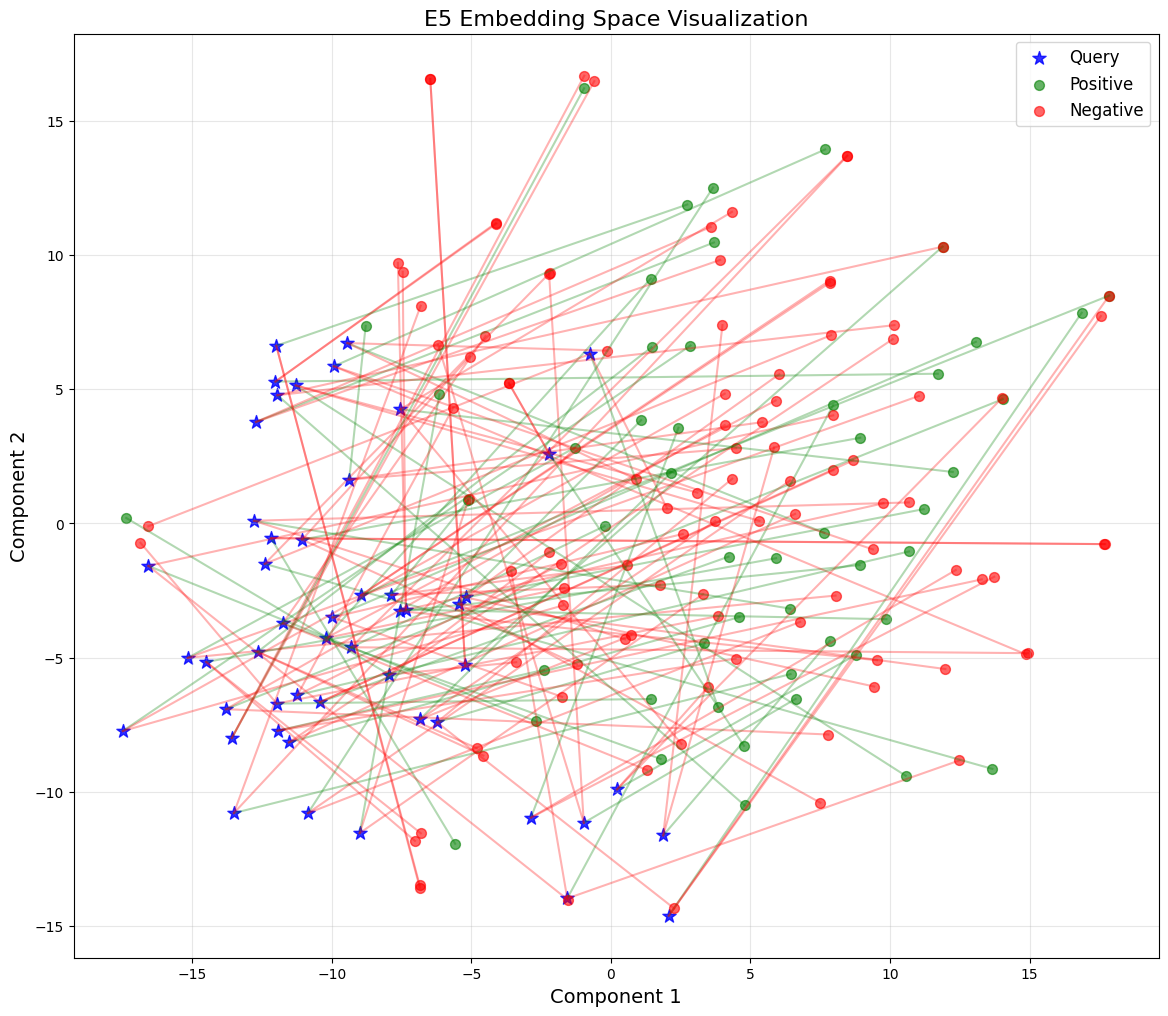

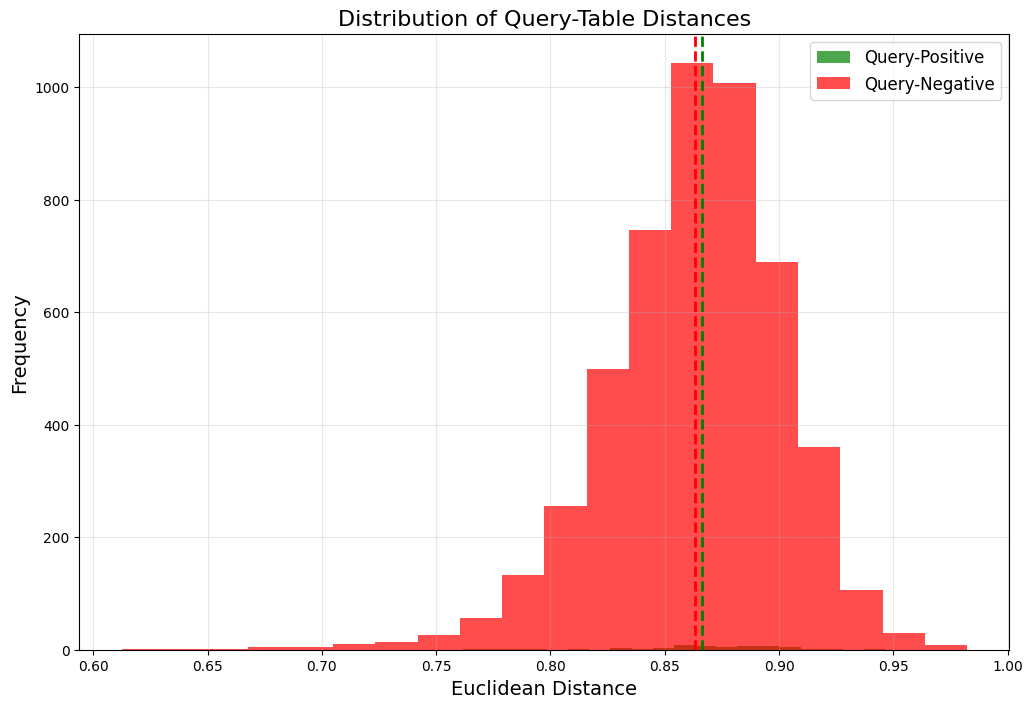


Distance Statistics:
Average Query-Positive Distance: 0.8662
Average Query-Negative Distance: 0.8631
Distance Ratio (Pos/Neg): 1.0036


In [8]:
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.random_projection import GaussianRandomProjection
import numpy as np
import faiss
import json
from sklearn.metrics.pairwise import cosine_similarity
import matplotlib.pyplot as plt
import random
import matplotlib.lines as mlines
from typing import List, Dict, Tuple
from tqdm import tqdm
import os

class EmbeddingVisualizer:
    def __init__(self, base_dir: str, prefix: str = "e5", output_dir: str = "visualization_output"):
        """
        Initialize the visualizer with paths and configuration.
        
        Args:
            base_dir: Base directory containing the FAISS indices
            prefix: Prefix for the index files (e.g., "e5", "splade", etc.)
            output_dir: Directory to save visualization outputs
        """
        self.base_dir = base_dir
        self.prefix = prefix
        self.output_dir = output_dir
        os.makedirs(output_dir, exist_ok=True)
        
        # Load indices and metadata
        self.load_indices()
        self.load_metadata()
        self.create_mappings()

    def load_indices(self):
        """Load FAISS indices."""
        print("Loading FAISS indices...")
        try:
            self.positive_index = faiss.read_index(f"{self.base_dir}/{self.prefix}_positive_tables_index.faiss")
            self.negative_index = faiss.read_index(f"{self.base_dir}/{self.prefix}_negative_tables_index.faiss")
            self.query_index = faiss.read_index(f"{self.base_dir}/{self.prefix}_queries_index.faiss")
        except Exception as e:
            raise Exception(f"Error loading FAISS indices: {str(e)}")

    def load_metadata(self):
        """Load metadata files."""
        print("Loading metadata...")
        try:
            with open(f"{self.prefix}_positive_metadata.json", "r") as f:
                self.positive_metadata = json.load(f)
            with open(f"{self.prefix}_negative_metadata.json", "r") as f:
                self.negative_metadata = json.load(f)
            with open(f"{self.prefix}_query_metadata.json", "r") as f:
                self.query_metadata = json.load(f)
        except Exception as e:
            raise Exception(f"Error loading metadata: {str(e)}")

    def extract_embeddings(self):
        """Extract embeddings from FAISS indices."""
        print("Extracting embeddings...")
        
        def extract_from_index(index):
            embeddings = np.zeros((index.ntotal, index.d), dtype=np.float32)
            for i in range(index.ntotal):
                embeddings[i] = index.reconstruct(i)
            return embeddings

        self.positive_embeddings = extract_from_index(self.positive_index)
        self.negative_embeddings = extract_from_index(self.negative_index)
        self.query_embeddings = extract_from_index(self.query_index)

        print(f"Extracted embeddings shapes:")
        print(f"Positive: {self.positive_embeddings.shape}")
        print(f"Negative: {self.negative_embeddings.shape}")
        print(f"Query: {self.query_embeddings.shape}")

    def create_mappings(self):
        """Create mappings from query IDs to indices."""
        self.qid_to_query_idx = {}
        self.qid_to_pos_idx = {}
        self.qid_to_neg_idx = {}

        for idx, item in enumerate(self.query_metadata):
            qid = item.get("qid")
            if qid:
                if qid not in self.qid_to_query_idx:
                    self.qid_to_query_idx[qid] = []
                self.qid_to_query_idx[qid].append(idx)

        for idx, item in enumerate(self.positive_metadata):
            qid = item.get("qid")
            if qid:
                if qid not in self.qid_to_pos_idx:
                    self.qid_to_pos_idx[qid] = []
                self.qid_to_pos_idx[qid].append(idx)

        for idx, item in enumerate(self.negative_metadata):
            qid = item.get("qid")
            if qid:
                if qid not in self.qid_to_neg_idx:
                    self.qid_to_neg_idx[qid] = []
                self.qid_to_neg_idx[qid].append(idx)

    def prepare_visualization_data(self, max_qids: int = 50, max_neg_per_query: int = 2):
        """Prepare data for visualization."""
        # Find common query IDs
        common_qids = set(self.qid_to_query_idx.keys()) & \
                     set(self.qid_to_pos_idx.keys()) & \
                     set(self.qid_to_neg_idx.keys())
        print(f"Found {len(common_qids)} common query IDs")

        # Sample if needed
        if len(common_qids) > max_qids:
            common_qids = set(random.sample(list(common_qids), max_qids))

        # Create triplets
        self.triplets = []
        self.query_embs = []
        self.pos_embs = []
        self.neg_embs = []

        for qid in tqdm(common_qids, desc="Creating triplets"):
            query_idx = self.qid_to_query_idx[qid][0]
            pos_idx = self.qid_to_pos_idx[qid][0]
            neg_indices = self.qid_to_neg_idx[qid][:max_neg_per_query]

            query_emb = self.query_embeddings[query_idx]
            pos_emb = self.positive_embeddings[pos_idx]

            self.query_embs.append(query_emb)
            self.pos_embs.append(pos_emb)

            for neg_idx in neg_indices:
                neg_emb = self.negative_embeddings[neg_idx]
                self.neg_embs.append(neg_emb)
                self.triplets.append((query_emb, pos_emb, neg_emb, qid))

        self.query_embs = np.array(self.query_embs)
        self.pos_embs = np.array(self.pos_embs)
        self.neg_embs = np.array(self.neg_embs)

        print(f"Created {len(self.triplets)} triplets for visualization")

    def reduce_dimensions(self, method: str = 'tsne'):
        """Apply dimensionality reduction."""
        all_embeddings = np.vstack([self.query_embs, self.pos_embs, self.neg_embs])
        
        if method == 'tsne':
            # First reduce with PCA to 50 dimensions
            pca = PCA(n_components=50)
            reduced = pca.fit_transform(all_embeddings)
            
            # Then apply t-SNE
            tsne = TSNE(n_components=2, random_state=42, perplexity=30)
            final = tsne.fit_transform(reduced)
        elif method == 'pca':
            pca = PCA(n_components=2)
            final = pca.fit_transform(all_embeddings)
        else:
            raise ValueError(f"Unknown reduction method: {method}")

        # Split results
        n_queries = len(self.query_embs)
        n_pos = len(self.pos_embs)
        
        self.query_2d = final[:n_queries]
        self.pos_2d = final[n_queries:n_queries + n_pos]
        self.neg_2d = final[n_queries + n_pos:]

    def plot_embeddings(self, show_connections: bool = True):
        """Create visualization plots."""
        # Basic scatter plot
        plt.figure(figsize=(14, 12))
        plt.scatter(self.query_2d[:, 0], self.query_2d[:, 1], 
                   c='blue', label='Query', s=100, alpha=0.8, marker='*')
        plt.scatter(self.pos_2d[:, 0], self.pos_2d[:, 1], 
                   c='green', label='Positive', s=50, alpha=0.6)
        plt.scatter(self.neg_2d[:, 0], self.neg_2d[:, 1], 
                   c='red', label='Negative', s=50, alpha=0.6)

        if show_connections:
            neg_idx = 0
            for i, q_coord in enumerate(self.query_2d):
                # Connection to positive example
                p_coord = self.pos_2d[i]
                plt.plot([q_coord[0], p_coord[0]], [q_coord[1], p_coord[1]], 
                        'g-', alpha=0.3)
                
                # Connections to negative examples
                for _ in range(2):  # Up to 2 negatives per query
                    if neg_idx < len(self.neg_2d):
                        n_coord = self.neg_2d[neg_idx]
                        plt.plot([q_coord[0], n_coord[0]], [q_coord[1], n_coord[1]], 
                                'r-', alpha=0.3)
                        neg_idx += 1

        plt.title(f'{self.prefix.upper()} Embedding Space Visualization', fontsize=16)
        plt.xlabel('Component 1', fontsize=14)
        plt.ylabel('Component 2', fontsize=14)
        plt.legend(fontsize=12)
        plt.grid(True, alpha=0.3)
        plt.savefig(f"{self.output_dir}/{self.prefix}_embeddings.png", dpi=300, bbox_inches='tight')
        plt.show()

    def plot_distance_distributions(self):
        """Plot distance distributions and calculate statistics."""
        # Calculate distances between query-positive pairs
        query_pos_distances = []
        query_neg_distances = []
        
        # Get query distances to positives
        for q, p in zip(self.query_embs, self.pos_embs):
            query_pos_distances.append(np.linalg.norm(q - p))
        
        # Get query distances to negatives
        for i, q in enumerate(self.query_embs):
            for n in self.neg_embs:
                query_neg_distances.append(np.linalg.norm(q - n))
        
        # Plot distributions
        plt.figure(figsize=(12, 8))
        plt.hist(query_pos_distances, bins=20, alpha=0.7, 
                label='Query-Positive', color='green')
        plt.hist(query_neg_distances, bins=20, alpha=0.7, 
                label='Query-Negative', color='red')
        
        # Add mean lines
        mean_pos = np.mean(query_pos_distances)
        mean_neg = np.mean(query_neg_distances) if query_neg_distances else 0
        plt.axvline(mean_pos, color='green', linestyle='dashed', linewidth=2)
        if query_neg_distances:
            plt.axvline(mean_neg, color='red', linestyle='dashed', linewidth=2)
    
        plt.title('Distribution of Query-Table Distances', fontsize=16)
        plt.xlabel('Euclidean Distance', fontsize=14)
        plt.ylabel('Frequency', fontsize=14)
        plt.legend(fontsize=12)
        plt.grid(True, alpha=0.3)
        plt.savefig(f"{self.output_dir}/{self.prefix}_distances.png", dpi=300, bbox_inches='tight')
        plt.show()
    
        # Print statistics
        print("\nDistance Statistics:")
        print(f"Average Query-Positive Distance: {mean_pos:.4f}")
        if query_neg_distances:
            print(f"Average Query-Negative Distance: {mean_neg:.4f}")
            print(f"Distance Ratio (Pos/Neg): {mean_pos/mean_neg:.4f}")

def main():
    # Initialize visualizer
    viz = EmbeddingVisualizer(
        base_dir="/home/mvyas7/TRIM-QA/Summer-Research/results/embeddings",
        prefix="e5",
        output_dir="embedding_visualizations"
    )
    
    # Extract embeddings
    viz.extract_embeddings()
    
    # Prepare visualization data
    viz.prepare_visualization_data(max_qids=50, max_neg_per_query=2)
    
    # Reduce dimensions
    viz.reduce_dimensions(method='tsne')
    
    # Create visualizations
    viz.plot_embeddings(show_connections=True)
    viz.plot_distance_distributions()

if __name__ == "__main__":
    main()

## Training

Loading dataset...
Loading metadata from /home/mvyas7/TRIM-QA/Summer-Research/results/embeddings/e5_query_metadata.json...
Loading FAISS indices...
Loading metadata mappings...
Creating mappings from query IDs to FAISS indices...
Dataset ready with 1067 valid triplets
Starting triplet model training with optimized parameters...
Training set size: 853, Validation set size: 214
Embedding dimension from FAISS index: 1024
Training model with optimized hyperparameters...


Epoch 1/30 Training:   0%|          | 0/27 [00:00<?, ?it/s]

Validation: 100%|██████████| 7/7 [00:00<00:00, 717.20it/s]


Epoch [1/30], Train Loss: 0.6927, Val Loss: 0.6929, LR: 0.005000
Model saved to best_modelPruned.pth
New best validation loss: 0.6929, model saved


Validation: 100%|██████████| 7/7 [00:00<00:00, 728.92it/s]


...

Epoch [28/30], Train Loss: 0.5408, Val Loss: 0.6474, LR: 0.001250


Validation: 100%|██████████| 7/7 [00:00<00:00, 724.89it/s]


Epoch [29/30], Train Loss: 0.5373, Val Loss: 0.6264, LR: 0.001250


Validation: 100%|██████████| 7/7 [00:00<00:00, 743.61it/s]


Epoch [30/30], Train Loss: 0.5078, Val Loss: 0.6458, LR: 0.001250
Early stopping triggered after 30 epochs
Training complete


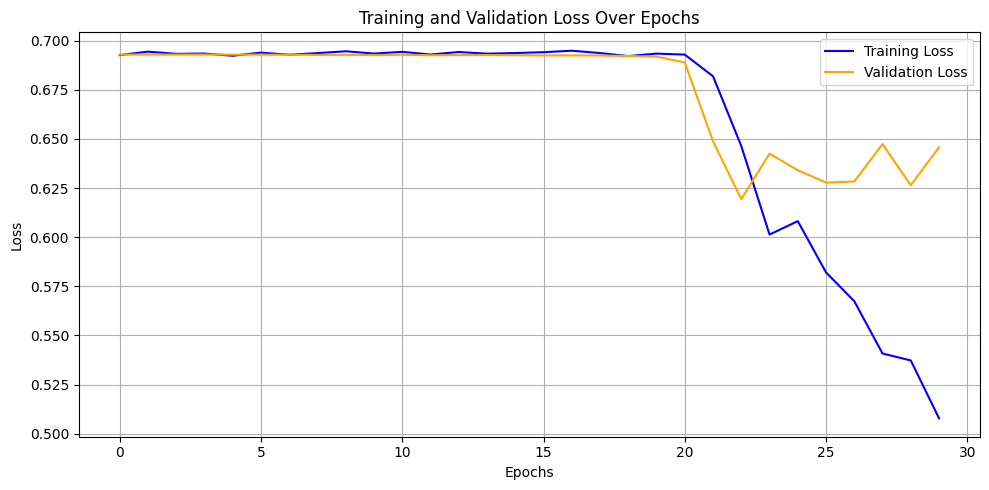

Model saved to optimized_triplet_model.pth
Training complete!
Model loaded from optimized_triplet_model.pth


Processing embeddings: 100%|██████████| 100/100 [00:00<00:00, 1192.06it/s]


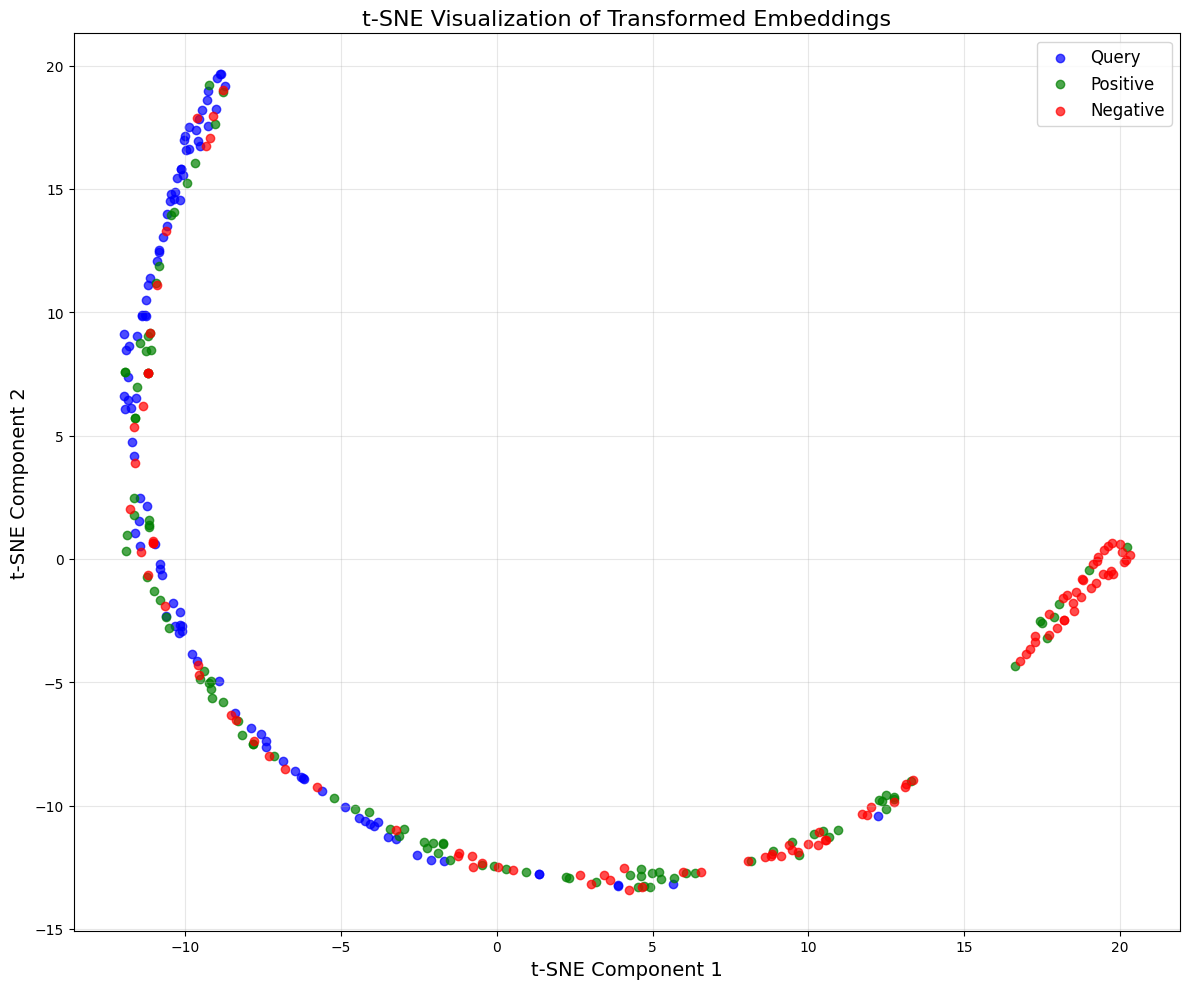


Distance Statistics:
Average Query-Positive Distance: 0.4066
Average Query-Negative Distance: 0.9491
Distance Ratio (Negative/Positive): 2.3343
Process completed successfully!


In [12]:
"""
Enhanced Triplet Learning Model for Table Retrieval using FAISS embeddings

This code implements a triplet learning architecture to improve table retrieval.
It trains a neural network to encode query and table embeddings in a way that
semantically related queries and tables are closer together in the embedding space,
while unrelated tables are pushed further apart.
"""

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, random_split
import json
import numpy as np
import faiss
from typing import Dict, List, Tuple
from tqdm import tqdm
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE
import random
import os

class FAISSTripletDataset(Dataset):
    """
    Dataset class that loads embeddings directly from FAISS indices
    and maps them to the metadata from the JSON file.
    """
    def __init__(self, metadata_file: str, 
                 query_index_path: str, 
                 positive_index_path: str, 
                 negative_index_path: str):
        print(f"Loading metadata from {metadata_file}...")
        with open(metadata_file, "r") as f:
            metadata_list = json.load(f)
        
        # Convert list to dictionary with qid as keys
        self.metadata = {item["qid"]: item for item in metadata_list}
        
        print(f"Loading FAISS indices...")
        self.query_index = faiss.read_index(query_index_path)
        self.positive_index = faiss.read_index(positive_index_path)
        self.negative_index = faiss.read_index(negative_index_path)
        
        print(f"Loading metadata mappings...")
        # Extract metadata prefix from the metadata_file name
        prefix = os.path.basename(metadata_file).split('_')[0] if '_' in metadata_file else ""
        metadata_dir = os.path.dirname(metadata_file)
        metadata_prefix = f"{prefix}_" if prefix else ""
        
        with open(os.path.join(metadata_dir, f"{metadata_prefix}positive_metadata.json"), "r") as f:
            self.positive_metadata = json.load(f)
        with open(os.path.join(metadata_dir, f"{metadata_prefix}negative_metadata.json"), "r") as f:
            self.negative_metadata = json.load(f)
        with open(os.path.join(metadata_dir, f"{metadata_prefix}query_metadata.json"), "r") as f:
            self.query_metadata = json.load(f)
        
        print("Creating mappings from query IDs to FAISS indices...")
        # Create mappings from qid to index in FAISS
        self.qid_to_query_idx = {}
        for idx, item in enumerate(self.query_metadata):
            self.qid_to_query_idx[item["qid"]] = idx
        
        self.qid_to_pos_idx = {}
        for idx, item in enumerate(self.positive_metadata):
            if item["qid"] not in self.qid_to_pos_idx:
                self.qid_to_pos_idx[item["qid"]] = []
            self.qid_to_pos_idx[item["qid"]].append(idx)
        
        self.qid_to_neg_idx = {}
        for idx, item in enumerate(self.negative_metadata):
            if item["qid"] not in self.qid_to_neg_idx:
                self.qid_to_neg_idx[item["qid"]] = []
            self.qid_to_neg_idx[item["qid"]].append(idx)
        
        # Store list of valid qids (those with query, positive, and negative embeddings)
        self.valid_qids = [qid for qid in self.metadata.keys() 
                          if qid in self.qid_to_query_idx 
                          and qid in self.qid_to_pos_idx 
                          and qid in self.qid_to_neg_idx]
        
        print(f"Dataset ready with {len(self.valid_qids)} valid triplets")

    def __len__(self):
        return len(self.valid_qids)

    def __getitem__(self, idx: int) -> tuple:
        qid = self.valid_qids[idx]
        
        # Get query embedding
        query_idx = self.qid_to_query_idx[qid]
        query_embedding = self._get_vector_from_index(self.query_index, query_idx)
        
        # Get positive embedding
        pos_idx = self.qid_to_pos_idx[qid][0]  # Take the first positive embedding
        pos_embedding = self._get_vector_from_index(self.positive_index, pos_idx)
        
        # Get negative embeddings
        neg_indices = self.qid_to_neg_idx[qid]
        neg_embeddings = [self._get_vector_from_index(self.negative_index, neg_idx) 
                         for neg_idx in neg_indices]
        
        return query_embedding, pos_embedding, neg_embeddings
    
    def _get_vector_from_index(self, index, idx):
        """Get a single vector from a FAISS index by its position."""
        if hasattr(index, 'reconstruct'):
            return index.reconstruct(idx)
        else:
            # For flat indices that don't have reconstruct method
            arr = np.empty((1, index.d), dtype=np.float32)
            index.reconstruct_n(idx, 1, arr)
            return arr[0]
    
    def get_query(self, idx: int) -> str:
        qid = self.valid_qids[idx]
        return self.metadata[qid]["query"]
    
    def get_positive_table_id(self, idx: int) -> str:
        qid = self.valid_qids[idx]
        return self.metadata[qid]["positive_table_id"]
    
    def get_hard_negatives(self, idx: int) -> List[str]:
        qid = self.valid_qids[idx]
        return self.metadata[qid]["hard_negatives"]
    
    def get_positive_content(self, idx: int) -> str:
        qid = self.valid_qids[idx]
        return self.metadata[qid].get("positive_content", "")
    
    def get_negative_contents(self, idx: int) -> List[str]:
        qid = self.valid_qids[idx]
        return self.metadata[qid].get("negative_contents", [])

class EnhancedTripletEncoder(nn.Module):
    """
    Enhanced neural network model that transforms input embeddings into a lower-dimensional space.
    Uses LayerNorm instead of InstanceNorm to avoid issues with spatial dimensions.
    """
    def __init__(self, embedding_dim: int, dropout_rate: float = 0.2):
        super(EnhancedTripletEncoder, self).__init__()
        # First layer
        self.fc1 = nn.Linear(embedding_dim, 512)
        self.norm1 = nn.LayerNorm(512)  # LayerNorm works with any input shape
        self.relu1 = nn.ReLU()
        self.dropout1 = nn.Dropout(dropout_rate)
        
        # Second layer
        self.fc2 = nn.Linear(512, 256)
        self.norm2 = nn.LayerNorm(256)
        self.relu2 = nn.ReLU()
        self.dropout2 = nn.Dropout(dropout_rate)
        
        # Third layer
        self.fc3 = nn.Linear(256, 128)
        
        # L2 normalization of final embeddings
        self.normalize_output = True
        
    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # First layer
        x = self.fc1(x)
        x = self.norm1(x)  # LayerNorm doesn't need extra dimensions
        x = self.relu1(x)
        x = self.dropout1(x)
        
        # Second layer
        x = self.fc2(x)
        x = self.norm2(x)
        x = self.relu2(x)
        x = self.dropout2(x)
        
        # Third layer
        x = self.fc3(x)
        
        # L2 normalization
        if self.normalize_output:
            x = F.normalize(x, p=2, dim=1)
            
        return x

class EnhancedTripletLoss(nn.Module):
    """
    Enhanced triplet loss implementation with options for hard or soft margin.
    """
    def __init__(self, margin: float = 0.3, soft_margin: bool = True):
        super(EnhancedTripletLoss, self).__init__()
        self.margin = margin
        self.soft_margin = soft_margin
        
    def forward(self, anchor: torch.Tensor, positive: torch.Tensor, negative: torch.Tensor) -> torch.Tensor:
        # Calculate distances
        pos_distance = torch.norm(anchor - positive, p=2, dim=1)
        neg_distance = torch.norm(anchor - negative, p=2, dim=1)
        
        # Calculate loss based on the chosen margin type
        if self.soft_margin:
            # Soft margin triplet loss using logarithm
            loss = torch.log1p(torch.exp(pos_distance - neg_distance))
        else:
            # Hard margin with traditional triplet loss
            loss = torch.clamp(pos_distance - neg_distance + self.margin, min=0.0)
        
        return loss.mean()

class EnhancedTripletTrainer:
    """
    Enhanced trainer class with learning rate scheduling, early stopping, and more robust training procedures.
    """
    def __init__(self, model: nn.Module, train_data: Dataset, val_data: Dataset, 
                 batch_size: int = 32, learning_rate: float = 5e-3, num_epochs: int = 30, 
                 margin: float = 0.3, weight_decay: float = 1e-4, scheduler_patience: int = 3,
                 early_stopping_patience: int = 7, soft_margin: bool = True):
        
        self.device = 'cuda' if torch.cuda.is_available() else 'cpu'
        self.model = model.to(self.device)
        self.train_data = train_data
        self.val_data = val_data
        self.batch_size = max(batch_size, 2)  # Ensure minimum batch size of 2
        self.learning_rate = learning_rate
        self.num_epochs = num_epochs
        self.weight_decay = weight_decay
        self.early_stopping_patience = early_stopping_patience
        self.scheduler_patience = scheduler_patience
        
        # Use the enhanced triplet loss
        self.criterion = EnhancedTripletLoss(margin=margin, soft_margin=soft_margin)
        
        # Optimizer with weight decay
        self.optimizer = optim.AdamW(
            self.model.parameters(),
            lr=learning_rate,
            weight_decay=weight_decay
        )
        
        # Learning rate scheduler
        self.scheduler = optim.lr_scheduler.ReduceLROnPlateau(
            self.optimizer,
            mode='min',
            factor=0.5,
            patience=scheduler_patience
        )
        
        # Data loaders with safe collate function
        self.train_dataloader = DataLoader(
            self.train_data, 
            batch_size=self.batch_size, 
            shuffle=True, 
            collate_fn=self.safe_collate_fn
        )
        
        self.val_dataloader = DataLoader(
            self.val_data, 
            batch_size=self.batch_size, 
            shuffle=False, 
            collate_fn=self.safe_collate_fn
        )
        
        self.train_losses = []
        self.val_losses = []

    def safe_collate_fn(self, batch):
        """Collate function that ensures we have at least 2 samples in a batch for training"""
        anchors, positives, negatives = [], [], []
        
        for anchor, positive, neg_embs in batch:
            if not neg_embs:  # Skip if no negatives
                continue
                
            anchors.append(anchor)
            positives.append(positive)
            # Select a random negative
            negatives.append(neg_embs[np.random.randint(len(neg_embs))])
        
        # If we don't have enough samples, return None
        if len(anchors) < 2:
            return None, None, None
            
        anchors = torch.tensor(np.array(anchors), dtype=torch.float32)
        positives = torch.tensor(np.array(positives), dtype=torch.float32)
        negatives = torch.tensor(np.array(negatives), dtype=torch.float32)
        
        return anchors, positives, negatives

    def train(self):
        """Train the model with early stopping and learning rate scheduling"""
        best_val_loss = float('inf')
        epochs_no_improve = 0
        
        for epoch in range(self.num_epochs):
            # Training phase
            self.model.train()
            total_train_loss = 0.0
            batch_count = 0
            
            for anchor, positive, negative in tqdm(self.train_dataloader, desc=f"Epoch {epoch+1}/{self.num_epochs} Training"):
                if anchor is None or anchor.size(0) < 2:
                    # Skip batches with fewer than 2 samples
                    continue
                    
                anchor = anchor.to(self.device)
                positive = positive.to(self.device)
                negative = negative.to(self.device)
                
                self.optimizer.zero_grad()
                
                # Forward pass
                anchor_embedding = self.model(anchor)
                positive_embedding = self.model(positive)
                negative_embedding = self.model(negative)
                
                # Calculate loss
                loss = self.criterion(anchor_embedding, positive_embedding, negative_embedding)
                
                # Backward pass
                loss.backward()
                
                # Gradient clipping to prevent exploding gradients
                torch.nn.utils.clip_grad_norm_(self.model.parameters(), max_norm=1.0)
                
                self.optimizer.step()
                
                total_train_loss += loss.item()
                batch_count += 1

            avg_train_loss = total_train_loss / batch_count if batch_count > 0 else 0
            
            # Validation phase
            avg_val_loss = self.validate()
            
            # Update learning rate based on validation performance
            self.scheduler.step(avg_val_loss)
            
            # Record losses
            self.train_losses.append(avg_train_loss)
            self.val_losses.append(avg_val_loss)
            
            # Get current learning rate
            current_lr = self.optimizer.param_groups[0]['lr']
            
            print(f"Epoch [{epoch+1}/{self.num_epochs}], "
                  f"Train Loss: {avg_train_loss:.4f}, Val Loss: {avg_val_loss:.4f}, "
                  f"LR: {current_lr:.6f}")
            
            # Check if we should save the model
            if avg_val_loss < best_val_loss:
                best_val_loss = avg_val_loss
                epochs_no_improve = 0
                self.save_model("best_modelPruned.pth")
                print(f"New best validation loss: {best_val_loss:.4f}, model saved")
            else:
                epochs_no_improve += 1
                
            # Early stopping
            if epochs_no_improve >= self.early_stopping_patience:
                print(f"Early stopping triggered after {epoch+1} epochs")
                break
        
        print("Training complete")
        return best_val_loss, self.train_losses, self.val_losses

    def validate(self):
        """Evaluate the model on validation data"""
        self.model.eval()
        total_val_loss = 0.0
        batch_count = 0
        
        with torch.no_grad():
            for anchor, positive, negative in tqdm(self.val_dataloader, desc="Validation"):
                if anchor is None or anchor.size(0) < 2:
                    # Skip batches with fewer than 2 samples
                    continue
                
                anchor = anchor.to(self.device)
                positive = positive.to(self.device)
                negative = negative.to(self.device)
                
                anchor_embedding = self.model(anchor)
                positive_embedding = self.model(positive)
                negative_embedding = self.model(negative)
                
                loss = self.criterion(anchor_embedding, positive_embedding, negative_embedding)
                total_val_loss += loss.item()
                batch_count += 1
        
        return total_val_loss / batch_count if batch_count > 0 else 0

    def save_model(self, path: str):
        """Save model weights to file"""
        torch.save(self.model.state_dict(), path)
        print(f"Model saved to {path}")

    def load_model(self, path: str):
        """Load model weights from file"""
        self.model.load_state_dict(torch.load(path, map_location=self.device))
        self.model.eval()
        print(f"Model loaded from {path}")

class TrainingPlotter:
    """Class to handle plotting of training and validation loss over epochs"""
    def __init__(self):
        self.train_losses = []
        self.val_losses = []

    def update(self, train_loss: float, val_loss: float):
        self.train_losses.append(train_loss)
        self.val_losses.append(val_loss)

    def plot(self):
        plt.figure(figsize=(10, 5))
        plt.plot(self.train_losses, label='Training Loss', color='blue')
        plt.plot(self.val_losses, label='Validation Loss', color='orange')
        plt.xlabel('Epochs')
        plt.ylabel('Loss')
        plt.title('Training and Validation Loss Over Epochs')
        plt.legend()
        plt.grid(True)
        plt.tight_layout()
        plt.savefig('training_validation_loss.png')
        plt.show()

def run_optimized_training(dataset):
    """Run training with optimized hyperparameters"""
    print("Starting triplet model training with optimized parameters...")
    
    # Data split with seed for reproducibility
    train_size = int(0.8 * len(dataset))
    val_size = len(dataset) - train_size
    train_dataset, val_dataset = random_split(
        dataset, 
        [train_size, val_size],
        generator=torch.Generator().manual_seed(42)
    )
    print(f"Training set size: {train_size}, Validation set size: {val_size}")
    
    # Get embedding dimension
    embedding_dim = dataset.query_index.d
    print(f"Embedding dimension from FAISS index: {embedding_dim}")
    
    # Create enhanced model with optimal parameters
    model = EnhancedTripletEncoder(
        embedding_dim=embedding_dim,
        dropout_rate=0.2
    ).to('cuda' if torch.cuda.is_available() else 'cpu')
    
    # Create trainer with optimized hyperparameters
    trainer = EnhancedTripletTrainer(
        model=model,
        train_data=train_dataset,
        val_data=val_dataset,
        batch_size=32,          # Larger batch size for better gradient estimates
        learning_rate=5e-3,     # Slightly higher learning rate
        num_epochs=30,          # More epochs with early stopping
        margin=0.3,             # Lower margin often works better
        soft_margin=True,       # Use soft margin for more stable training
        weight_decay=1e-4,      # L2 regularization
        scheduler_patience=3,   # LR reduction after 3 epochs without improvement
        early_stopping_patience=7  # Stop after 7 epochs without improvement
    )
    
    # Train model
    print("Training model with optimized hyperparameters...")
    _, train_losses, val_losses = trainer.train()
    
    # Plot results
    plotter = TrainingPlotter()
    for train_loss, val_loss in zip(train_losses, val_losses):
        plotter.update(train_loss, val_loss)
    plotter.plot()
    
    # Save final model
    trainer.save_model("optimized_triplet_model.pth")
    print("Training complete!")
    
    return trainer, model

def visualize_embeddings(model_path, dataset):
    """Visualize the embeddings after transformation through the model"""
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    
    # Get embedding dimension
    embedding_dim = dataset.query_index.d
    
    # Load the model
    model = EnhancedTripletEncoder(embedding_dim).to(device)
    model.load_state_dict(torch.load(model_path, map_location=device))
    model.eval()
    print(f"Model loaded from {model_path}")
    
    # Sample a subset of data for visualization
    sample_size = min(100, len(dataset))
    indices = random.sample(range(len(dataset)), sample_size)
    
    # Get embeddings
    query_embeddings, positive_embeddings, negative_embeddings = [], [], []
    
    with torch.no_grad():
        for idx in tqdm(indices, desc="Processing embeddings"):
            query_emb, pos_emb, neg_embs = dataset[idx]
            
            # Convert to tensors
            query = torch.tensor(query_emb, dtype=torch.float32).unsqueeze(0).to(device)
            pos = torch.tensor(pos_emb, dtype=torch.float32).unsqueeze(0).to(device)
            
            # Transform through model
            query_out = model(query).cpu().numpy()
            pos_out = model(pos).cpu().numpy()
            
            query_embeddings.append(query_out[0])
            positive_embeddings.append(pos_out[0])
            
            # Process one negative embedding per triplet
            if neg_embs:
                neg = torch.tensor(neg_embs[0], dtype=torch.float32).unsqueeze(0).to(device)
                neg_out = model(neg).cpu().numpy()
                negative_embeddings.append(neg_out[0])
    
    # Create visualization
    plt.figure(figsize=(12, 10))
    
    # Combine all embeddings for t-SNE
    all_embeddings = np.vstack([query_embeddings, positive_embeddings, negative_embeddings])
    labels = ['Query'] * len(query_embeddings) + ['Positive'] * len(positive_embeddings) + ['Negative'] * len(negative_embeddings)
    
    # Apply t-SNE
    tsne = TSNE(n_components=2, random_state=42, perplexity=min(30, sample_size-1))
    tsne_result = tsne.fit_transform(all_embeddings)
    
    # Plot points
    colors = {'Query': 'blue', 'Positive': 'green', 'Negative': 'red'}
    for label, color in colors.items():
        mask = [l == label for l in labels]
        plt.scatter(tsne_result[mask, 0], tsne_result[mask, 1], c=color, label=label, alpha=0.7)
    
    plt.title('t-SNE Visualization of Transformed Embeddings', fontsize=16)
    plt.xlabel('t-SNE Component 1', fontsize=14)
    plt.ylabel('t-SNE Component 2', fontsize=14)
    plt.legend(fontsize=12)
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.savefig('embedding_visualization.png')
    plt.show()
    
    # Calculate and print distance statistics
    q_p_distances = []
    q_n_distances = []
    
    for q, p, n in zip(query_embeddings, positive_embeddings, negative_embeddings[:len(query_embeddings)]):
        q_p_distances.append(np.linalg.norm(q - p))
        q_n_distances.append(np.linalg.norm(q - n))
    
    print("\nDistance Statistics:")
    print(f"Average Query-Positive Distance: {np.mean(q_p_distances):.4f}")
    print(f"Average Query-Negative Distance: {np.mean(q_n_distances):.4f}")
    print(f"Distance Ratio (Negative/Positive): {np.mean(q_n_distances) / np.mean(q_p_distances):.4f}")

def main():
    """Main execution function with options for grid search or optimized training"""
    # Set random seeds for reproducibility
    torch.manual_seed(42)
    np.random.seed(42)
    random.seed(42)
    
    print("Loading dataset...")
    triplet_dataset = FAISSTripletDataset(
        metadata_file="/home/mvyas7/TRIM-QA/Summer-Research/results/embeddings/e5_query_metadata.json",
        query_index_path="/home/mvyas7/TRIM-QA/Summer-Research/results/embeddings/e5_queries_index.faiss",
        positive_index_path="/home/mvyas7/TRIM-QA/Summer-Research/results/embeddings/e5_positive_tables_index.faiss",
        negative_index_path="/home/mvyas7/TRIM-QA/Summer-Research/results/embeddings/e5_negative_tables_index.faiss"
    )
    
    # Run optimized training with tuned hyperparameters
    trainer, model = run_optimized_training(triplet_dataset)
    
    # Visualize the results
    visualize_embeddings("optimized_triplet_model.pth", triplet_dataset)
    
    print("Process completed successfully!")

if __name__ == "__main__":
    main()

## Inference 

Starting table retrieval and ranking optimization process
Using device: cuda
Loading E5 embedding model...
Loading optimized triplet model...
Loading tables from /home/mvyas7/TRIM-QA/Summer-Research/nq_tables/interactions/test.jsonl...


Processing tables: 966it [00:00, 12959.00it/s]

Successfully loaded 896 tables
Loading test data from /home/mvyas7/TRIM-QA/Summer-Research/standalone_top100_test.dedup_by_text.xlsx...


Loaded 919 queries from test data
Excel file columns: ['QID', 'Orig Question', 'Answer', 'Gold Table Id', 'Rank of Gold Table (None = Not in Top 100)', 'Top 100']
Processing queries and reranking tables...


Processing queries:   0%|          | 0/919 [00:00<?, ?it/s]/home/mvyas7/TRIM-QA/Summer-Research/summer-research-venv3/lib/python3.13/site-packages/torch/nn/modules/module.py:1762: FutureWarning: `encoder_attention_mask` is deprecated and will be removed in version 4.55.0 for `BertSdpaSelfAttention.forward`.
  return forward_call(*args, **kwargs)
Processing queries:   2%|▏         | 18/919 [00:01<00:56, 15.85it/s]

...

Processed 919 unique queries (skipped 0 duplicates)
Calculating metrics...
Query #17: Not considered valid - Original rank is None but optimized rank is 2
Query #18: Not considered valid - Original rank is None but optimized rank is 1
Query #24: Not considered valid - Original rank is None but optimized rank is 1
Query #26: Not considered valid - Original rank is None but optimized rank is 6
Query #43: Not considered valid - Original rank is None but optimized rank is 1
Query #55: Not considered valid - Original rank is None but optimized rank is 3
Query #63: Not considered valid - Original rank is None but optimized rank is 1
Query #90: Not considered valid - Original rank is None but optimized rank is 3
Query #99: Not considered valid - Original rank is None but optimized rank is 2
Query #139: Not considered valid - Original rank is None but optimized rank is 1
Query #169: Not considered valid - Original rank is None but optimized rank is 2
Query #205: Not considered valid - Original

Generating original embedding samples: 100%|██████████| 400/400 [00:00<00:00, 22644.07it/s]


Collected 0 sample triplets for original embedding visualization
Not enough data collected for meaningful visualization

Generating t-SNE visualization of transformed embeddings...


Generating embedding samples: 100%|██████████| 400/400 [00:00<00:00, 24201.51it/s]

Collected 0 sample triplets for visualization
Not enough data collected for meaningful visualization

Analysis complete!


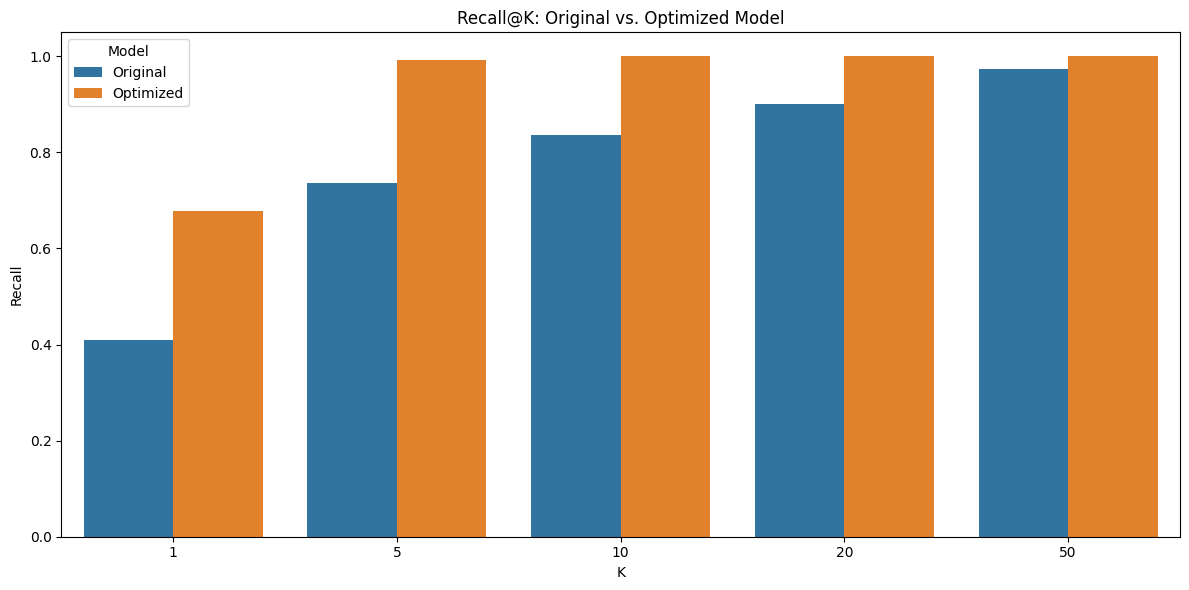

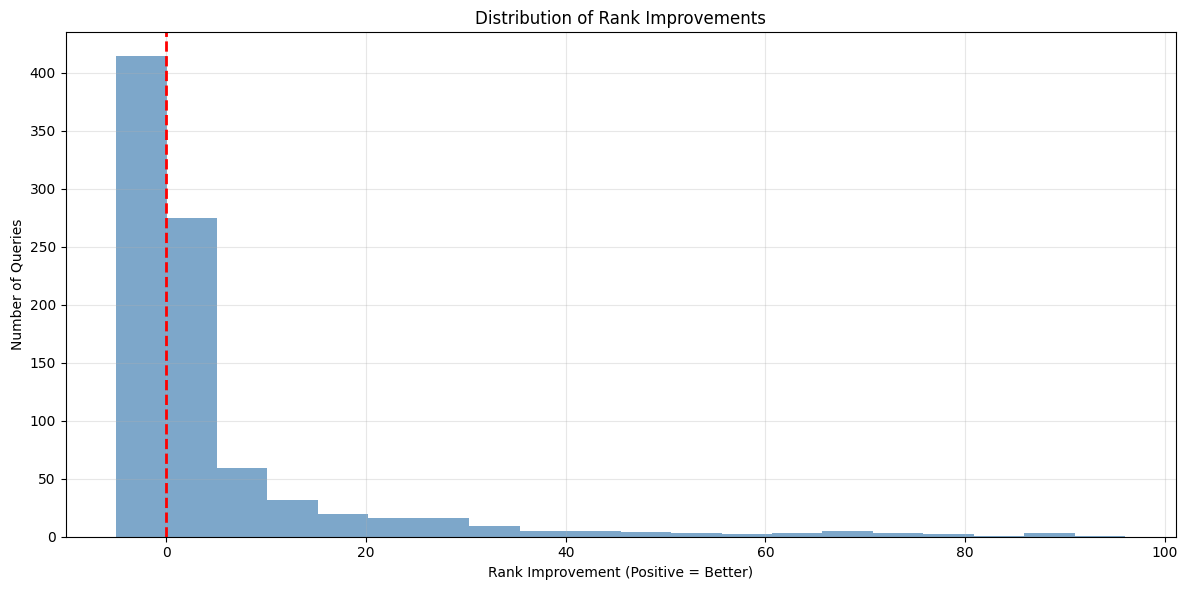

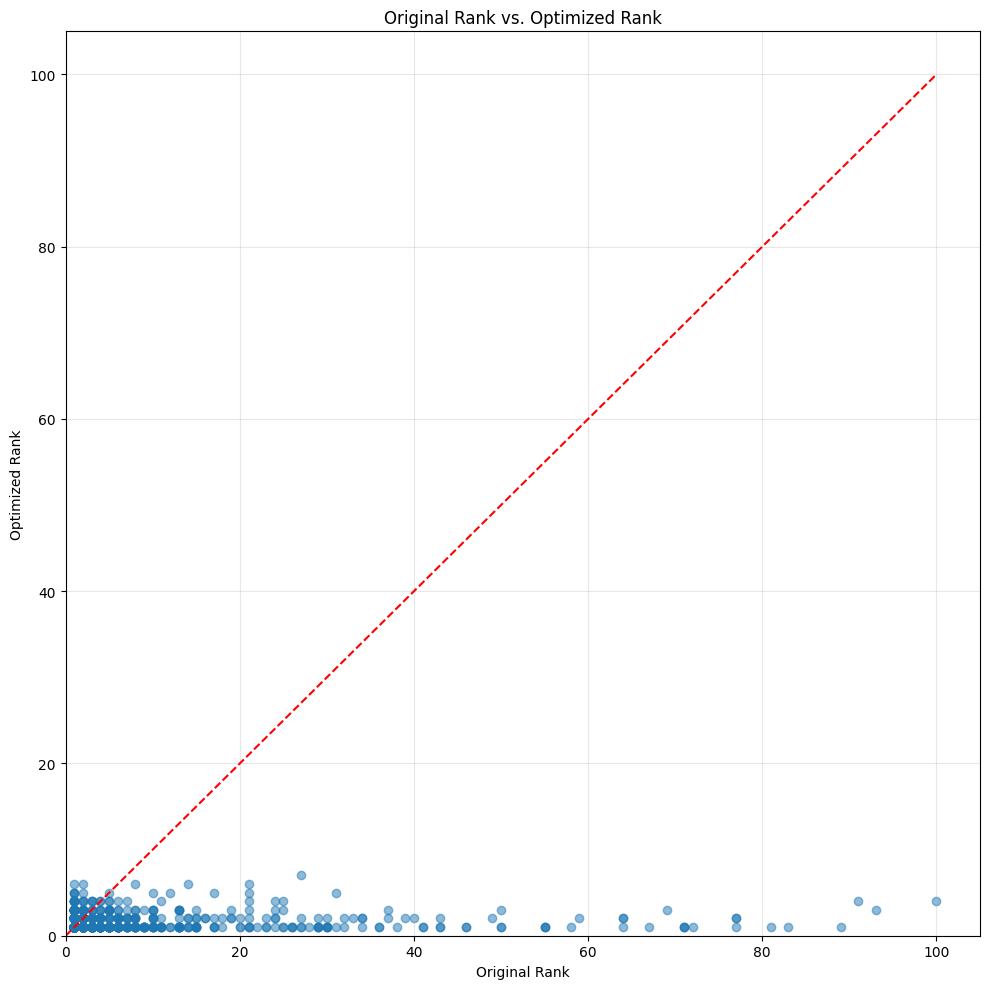

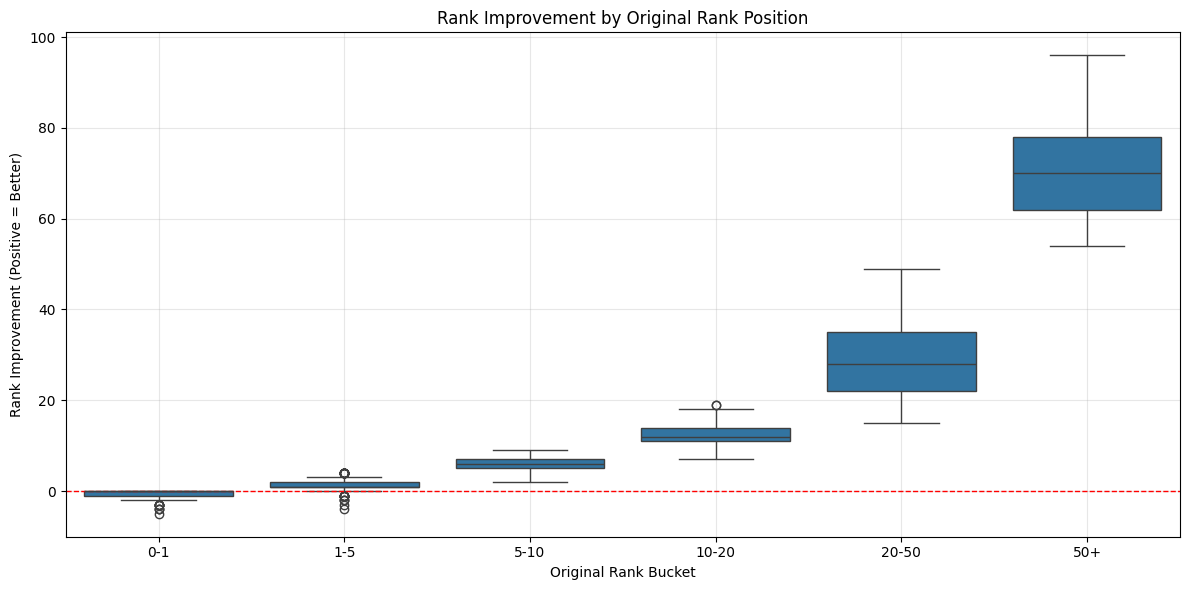

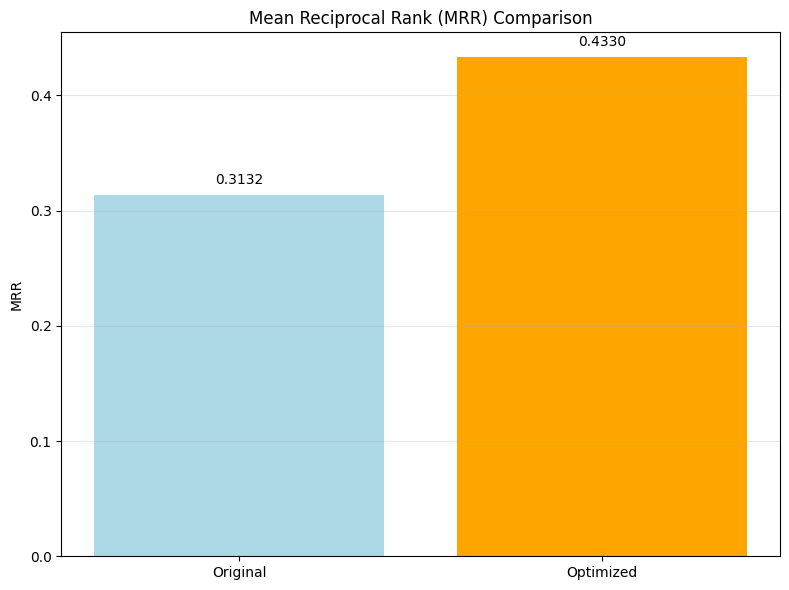

In [13]:
import os
import json
import torch
import torch.nn as nn
import torch.nn.functional as F
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
from transformers import AutoTokenizer, AutoModel
from typing import List, Dict, Tuple, Optional, Union

# Define paths
MODEL_PATH = "/home/mvyas7/TRIM-QA/Summer-Research/best_modelPruned.pth"
TEST_DATA_PATH = "/home/mvyas7/TRIM-QA/Summer-Research/standalone_top100_test.dedup_by_text.xlsx"
TABLES_PATH = "/home/mvyas7/TRIM-QA/Summer-Research/nq_tables/interactions/test.jsonl"
OUTPUT_DIR = "/home/mvyas7/TRIM-QA/Summer-Research/results"
STANDALONE_RESULTS_PATH = "/home/mvyas7/TRIM-QA/Summer-Research/standalone_top100_test.jsonl"

# Create output directory if it doesn't exist
os.makedirs(OUTPUT_DIR, exist_ok=True)

# Configuration
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
BATCH_SIZE = 16
MAX_SEQ_LENGTH = 512
RECALL_POSITIONS = [1, 5, 10, 20, 50]  # Recall@K positions to evaluate

class EnhancedTripletEncoder(nn.Module):
    """
    Neural network to transform embeddings into a more semantically meaningful space
    by applying the triplet loss optimization learned during training.
    """
    def __init__(self, embedding_dim=1024, dropout_rate=0.2):
        super(EnhancedTripletEncoder, self).__init__()
        # First layer
        self.fc1 = nn.Linear(embedding_dim, 512)
        self.norm1 = nn.LayerNorm(512)
        self.relu1 = nn.ReLU()
        self.dropout1 = nn.Dropout(dropout_rate)
        
        # Second layer
        self.fc2 = nn.Linear(512, 256)
        self.norm2 = nn.LayerNorm(256)
        self.relu2 = nn.ReLU()
        self.dropout2 = nn.Dropout(dropout_rate)
        
        # Third layer
        self.fc3 = nn.Linear(256, 128)
        
        # L2 normalization of final embeddings
        self.normalize_output = True
        
    def forward(self, x):
        # First layer
        x = self.fc1(x)
        x = self.norm1(x)
        x = self.relu1(x)
        x = self.dropout1(x)
        
        # Second layer
        x = self.fc2(x)
        x = self.norm2(x)
        x = self.relu2(x)
        x = self.dropout2(x)
        
        # Third layer
        x = self.fc3(x)
        
        # L2 normalization
        if self.normalize_output:
            x = F.normalize(x, p=2, dim=1)
            
        return x

# def load_standalone_results(file_path: str) -> Dict[str, List[Dict[str, Union[str, float]]]]:
#     """Load results from standalone ranking file."""
#     results = {}
#     with open(file_path, 'r') as f:
#         for line in f:
#             data = json.loads(line)
#             query_id = data['query_id']
#             results[query_id] = data['results']
#     return results

def load_jsonl_tables(file_path: str) -> Dict[str, dict]:
    """Load all tables from JSONL file into a dictionary keyed by tableId."""
    tables = {}
    
    print(f"Loading tables from {file_path}...")
    with open(file_path, 'r', encoding='utf-8') as f:
        for line in tqdm(f, desc="Processing tables"):
            if not line.strip():
                continue
                
            try:
                item = json.loads(line)
                if 'table' in item and 'tableId' in item['table']:
                    table_id = item['table']['tableId']
                    tables[table_id] = item['table']
            except json.JSONDecodeError:
                print(f"Error parsing JSON line: {line[:100]}...")
                
    print(f"Successfully loaded {len(tables)} tables")
    return tables

def prepare_table_text(table_data: dict) -> str:
    """Convert table data into a structured text representation."""
    # Start with document title
    doc_title = table_data.get('documentTitle', '')
    text_parts = [f"Title: {doc_title}"]
    
    # Extract column headers
    if 'columns' in table_data:
        headers = [col.get('text', '') for col in table_data['columns']]
        headers_text = ' | '.join(header for header in headers if header)
        text_parts.append(f"Headers: {headers_text}")
    
    # Extract rows
    if 'rows' in table_data:
        for i, row in enumerate(table_data['rows']):
            if 'cells' in row:
                row_values = [cell.get('text', '') for cell in row['cells']]
                row_text = ' | '.join(value for value in row_values if value)
                text_parts.append(f"Row {i+1}: {row_text}")
    
    return '\n'.join(text_parts)

def parse_top_tables(top_tables_str: str) -> List[str]:
    """Parse the top tables string into a list of table IDs."""
    if isinstance(top_tables_str, list):
        # Already a list
        return [item[0] for item in top_tables_str] if top_tables_str and isinstance(top_tables_str[0], tuple) else top_tables_str
    
    try:
        # Try to evaluate as Python literal (list of tuples)
        tables_with_scores = eval(top_tables_str)
        return [item[0] for item in tables_with_scores]
    except:
        # If that fails, try other formats
        if isinstance(top_tables_str, str):
            if '[' in top_tables_str and '(' in top_tables_str:
                # Try to extract table IDs using string manipulation
                parts = top_tables_str.replace('[', '').replace(']', '').split('),')
                return [p.split("'")[1] for p in parts if "'" in p]
            else:
                # Simple comma or space separated list
                return top_tables_str.replace(',', ' ').split()
    
    print(f"Warning: Could not parse top tables: {top_tables_str[:100]}...")
    return []

def generate_embeddings(tokenizer, model, texts: List[str], prefix: str, batch_size: int = 8) -> torch.Tensor:
    """Generate embeddings for a list of texts using the specified model."""
    # Add the appropriate prefix to each text
    prefixed_texts = [f"{prefix} {text}" for text in texts]
    all_embeddings = []
    
    # Process in batches
    for i in range(0, len(prefixed_texts), batch_size):
        batch_texts = prefixed_texts[i:i+batch_size]
        
        # Tokenize
        inputs = tokenizer(
            batch_texts, 
            padding=True, 
            truncation=True, 
            max_length=MAX_SEQ_LENGTH, 
            return_tensors="pt"
        ).to(DEVICE)
        
        # Generate embeddings
        with torch.no_grad():
            outputs = model(**inputs)
            # Get CLS token embedding (first token)
            embeddings = outputs.last_hidden_state[:, 0]
            # Normalize
            embeddings = F.normalize(embeddings, p=2, dim=1)
            all_embeddings.append(embeddings)
    
    # Concatenate all batch embeddings
    if all_embeddings:
        return torch.cat(all_embeddings, dim=0)
    else:
        return torch.tensor([])

def calculate_recall_at_k(gold_ranks: List[Optional[int]], k_values: List[int]) -> Dict[str, float]:
    """Calculate recall@k for each k in k_values."""
    results = {}
    
    for k in k_values:
        # For each query, check if gold table is in top-k
        recall = sum(1 for rank in gold_ranks if rank is not None and rank <= k) / max(1, len(gold_ranks))
        results[f'recall@{k}'] = recall
    
    return results

def calculate_mrr(gold_ranks: List[Optional[int]]) -> float:
    """Calculate Mean Reciprocal Rank."""
    # Reciprocal rank is 1/rank (add 1 to rank since ranks are 0-indexed)
    reciprocal_ranks = [1/(rank+1) if rank is not None else 0 for rank in gold_ranks]
    return sum(reciprocal_ranks) / max(1, len(reciprocal_ranks))

def visualize_original_embeddings(df, all_tables, e5_tokenizer, e5_model, n_samples=50):
    """
    Create t-SNE visualization of original E5 embeddings (before transformation)
    to compare with the transformed embeddings visualization.
    
    Args:
        df: DataFrame containing test queries
        all_tables: Dictionary of tables
        e5_tokenizer: E5 tokenizer
        e5_model: E5 model
        n_samples: Number of query-table sets to sample for visualization
    """
    from sklearn.manifold import TSNE
    import matplotlib.pyplot as plt
    import numpy as np
    import random
    import matplotlib.lines as mlines
    
    # Initialize storage for visualization data
    viz_data = []
    processed_query_ids = set()
    
    print(f"Collecting sample data for t-SNE visualization of original embeddings...")
    
    # Sample rows from the dataframe - use a larger pool to ensure we get enough valid samples
    sample_indices = random.sample(range(len(df)), min(len(df), n_samples*4))
    
    for idx in tqdm(sample_indices, desc="Generating original embedding samples"):
        row = df.iloc[idx]
        
        # Extract query information
        query_id = row['QID'] if 'QID' in df.columns else (row['query_id'] if 'query_id' in df.columns else None)
        
        # Skip if we've already processed this query ID or missing essential information
        if query_id is None or query_id in processed_query_ids:
            continue
        
        processed_query_ids.add(query_id)
        
        # Extract query text
        question = None
        col_name = 'Orig Question'
        if col_name in df.columns and pd.notna(row[col_name]):
            question = row[col_name]
        if question is None:
            continue
            
        # Extract decomposed question if available
        decomposed_question = None
        decomposed_col_name = 'Decomposed question'
        if decomposed_col_name in df.columns and pd.notna(row[decomposed_col_name]):
            decomposed_question = row[decomposed_col_name]
        query_text = decomposed_question if decomposed_question else question
        
        # Get gold table ID
        gold_table_id = None
        for col_name in ['Gold Table ID', 'Gold Table Id']:
            if col_name in df.columns and pd.notna(row[col_name]):
                gold_table_id = row[col_name]
                break
                
        if gold_table_id is None or gold_table_id not in all_tables:
            continue
        
        # Get top tables
        top_tables_str = None
        for col_name in ['Top 50 Table Array', 'Top 50 (TableIds,score)', 'Top 50 Tables']:
            if col_name in df.columns and pd.notna(row[col_name]):
                top_tables_str = row[col_name]
                break
                
        if top_tables_str is None:
            continue
            
        # Parse top tables
        top_table_ids = parse_top_tables(top_tables_str)
        if not top_table_ids:
            continue
            
        # Filter to get only tables that exist in our table collection
        valid_table_ids = [t for t in top_table_ids if t in all_tables]
        
        if len(valid_table_ids) < 3 or gold_table_id not in valid_table_ids:
            continue
            
        # Generate embeddings and rerank the tables
        table_texts = [prepare_table_text(all_tables[t]) for t in valid_table_ids]
        
        # Generate query embedding
        query_embedding = generate_embeddings(
            e5_tokenizer, e5_model, [query_text], "query:", batch_size=1
        )
        
        # Generate table embeddings
        table_embeddings = generate_embeddings(
            e5_tokenizer, e5_model, table_texts, "passage:", batch_size=BATCH_SIZE
        )
        
        if query_embedding.size(0) == 0 or table_embeddings.size(0) == 0:
            continue
        
        # Compute similarity scores with ORIGINAL embeddings
        similarities = torch.matmul(query_embedding, table_embeddings.t())
        similarities = similarities.squeeze().cpu().numpy()
        
        # Rank tables based on similarity
        ranked_indices = np.argsort(-similarities)  # Descending order
        ranked_table_ids = [valid_table_ids[i] for i in ranked_indices]
        
        # Find the gold table position in the original ranking
        if gold_table_id not in ranked_table_ids:
            continue
            
        gold_position = ranked_table_ids.index(gold_table_id)
        
        # Get the two tables immediately after the gold table in the ranking
        next_table_ids = []
        for i in range(1, 3):  # Get up to 2 tables after gold
            next_idx = gold_position + i
            if next_idx < len(ranked_table_ids):
                next_table_ids.append(ranked_table_ids[next_idx])
                
        # Need at least one table after gold
        if not next_table_ids:
            continue
            
        # If only one table after gold, duplicate it for consistent data structure
        if len(next_table_ids) == 1:
            next_table_ids.append(next_table_ids[0])
        
        # Prepare specific table texts for visualization
        gold_table_text = prepare_table_text(all_tables[gold_table_id])
        next_table_texts = [prepare_table_text(all_tables[t]) for t in next_table_ids]
        
        # Generate embeddings for just these selected tables
        selected_embeddings = generate_embeddings(
            e5_tokenizer, e5_model, 
            [gold_table_text] + next_table_texts, 
            "passage:", batch_size=3
        )
        
        if selected_embeddings.size(0) < 3:
            continue
        
        # Store this sample - using original embeddings
        viz_data.append({
            'query_id': query_id,
            'query_text': query_text[:100] + "..." if len(query_text) > 100 else query_text,
            'query_embedding': query_embedding[0].cpu().numpy(),
            'gold_table_embedding': selected_embeddings[0].cpu().numpy(),
            'next_table1_embedding': selected_embeddings[1].cpu().numpy(),
            'next_table2_embedding': selected_embeddings[2].cpu().numpy(),
            'gold_table_id': gold_table_id,
            'next_table_ids': next_table_ids,
            'gold_position': gold_position + 1  # 1-indexed for display
        })
        
        # Break if we have enough samples
        if len(viz_data) >= n_samples:
            break
    
    print(f"Collected {len(viz_data)} sample triplets for original embedding visualization")
    
    if len(viz_data) < 5:
        print("Not enough data collected for meaningful visualization")
        return
    
    # Extract all embeddings for t-SNE
    query_embeddings = np.array([d['query_embedding'] for d in viz_data])
    gold_embeddings = np.array([d['gold_table_embedding'] for d in viz_data])
    next1_embeddings = np.array([d['next_table1_embedding'] for d in viz_data])
    next2_embeddings = np.array([d['next_table2_embedding'] for d in viz_data])
    
    # Combine all embeddings
    all_embeddings = np.vstack([
        query_embeddings, 
        gold_embeddings, 
        next1_embeddings, 
        next2_embeddings
    ])
    
    # Apply t-SNE
    print("Applying t-SNE dimensionality reduction...")
    tsne = TSNE(n_components=2, random_state=42, perplexity=min(30, len(all_embeddings)//4))
    tsne_results = tsne.fit_transform(all_embeddings)
    
    # Split results back into groups
    query_tsne = tsne_results[:len(query_embeddings)]
    gold_tsne = tsne_results[len(query_embeddings):len(query_embeddings)+len(gold_embeddings)]
    next_tsne = tsne_results[len(query_embeddings)+len(gold_embeddings):]
    
    # Create visualization
    plt.figure(figsize=(14, 10))
    
    # Plot points
    plt.scatter(query_tsne[:, 0], query_tsne[:, 1], c='blue', marker='*', s=150, label='Query', alpha=0.8)
    plt.scatter(gold_tsne[:, 0], gold_tsne[:, 1], c='green', s=80, label='Gold Table', alpha=0.7)
    plt.scatter(next_tsne[:, 0], next_tsne[:, 1], c='orange', s=60, label='Next-Ranked Table', alpha=0.6)
    
    # Draw lines from queries to their tables
    for i in range(len(query_tsne)):
        # Line to gold table (green)
        plt.plot([query_tsne[i, 0], gold_tsne[i, 0]], [query_tsne[i, 1], gold_tsne[i, 1]], 
                 'g-', alpha=0.5, linewidth=1)
        
        # Lines to next-ranked tables (orange)
        idx1 = i * 2
        idx2 = i * 2 + 1
        if idx2 < len(next_tsne):
            plt.plot([query_tsne[i, 0], next_tsne[idx1, 0]], [query_tsne[i, 1], next_tsne[idx1, 1]], 
                     'orange', alpha=0.3, linewidth=0.7)
            plt.plot([query_tsne[i, 0], next_tsne[idx2, 0]], [query_tsne[i, 1], next_tsne[idx2, 1]], 
                     'orange', alpha=0.3, linewidth=0.7)
    
    # Custom legend
    query_marker = mlines.Line2D([], [], color='blue', marker='*', linestyle='None',
                              markersize=10, label='Query')
    gold_marker = mlines.Line2D([], [], color='green', marker='o', linestyle='None',
                              markersize=7, label='Gold Table')
    next_marker = mlines.Line2D([], [], color='orange', marker='o', linestyle='None',
                                markersize=6, label='Next-Ranked Table')
    gold_line = mlines.Line2D([], [], color='green', marker='None', linestyle='-',
                           alpha=0.5, label='Query-Gold Connection')
    next_line = mlines.Line2D([], [], color='orange', marker='None', linestyle='-',
                              alpha=0.3, label='Query-Next Connection')
    
    plt.legend(handles=[query_marker, gold_marker, next_marker, gold_line, next_line], 
               loc='best', fontsize=12)
    
    plt.title(f't-SNE Visualization of Original E5 Embeddings ({len(viz_data)} queries)', fontsize=16)
    plt.xlabel('t-SNE Component 1', fontsize=14)
    plt.ylabel('t-SNE Component 2', fontsize=14)
    plt.grid(True, linestyle='--', alpha=0.3)
    plt.tight_layout()
    
    # Save and show the plot
    plt.savefig(os.path.join(OUTPUT_DIR, 'tsne_original_embeddings.png'), dpi=300)
    plt.show()
    
    # Calculate and visualize distances
    query_gold_distances = []
    query_next_distances = []
    
    for i in range(len(query_embeddings)):
        # Distance to gold table
        query_gold_distances.append(np.linalg.norm(query_embeddings[i] - gold_embeddings[i]))
        
        # Distances to next tables
        query_next_distances.append(np.linalg.norm(query_embeddings[i] - next1_embeddings[i]))
        query_next_distances.append(np.linalg.norm(query_embeddings[i] - next2_embeddings[i]))
    
    # Create histogram
    plt.figure(figsize=(12, 6))
    plt.hist(query_gold_distances, bins=15, alpha=0.7, label='Query-Gold Distance', color='green')
    plt.hist(query_next_distances, bins=15, alpha=0.5, label='Query-Next Distance', color='orange')
    
    # Add vertical lines for mean distances
    mean_gold_dist = np.mean(query_gold_distances)
    mean_next_dist = np.mean(query_next_distances)
    plt.axvline(mean_gold_dist, color='green', linestyle='dashed', linewidth=2, 
                label=f'Mean Gold Distance: {mean_gold_dist:.4f}')
    plt.axvline(mean_next_dist, color='orange', linestyle='dashed', linewidth=2, 
                label=f'Mean Next Distance: {mean_next_dist:.4f}')
    
    plt.title('Distance Distribution: Query to Tables (Original E5 Space)', fontsize=16)
    plt.xlabel('Euclidean Distance in Original Space', fontsize=14)
    plt.ylabel('Frequency', fontsize=14)
    plt.legend(fontsize=12)
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, 'original_distances_histogram.png'), dpi=300)
    plt.show()
    
    # Create an additional scatter plot showing gold position vs. distance separation
    plt.figure(figsize=(10, 6))
    gold_positions = [d['gold_position'] for d in viz_data]
    distance_diffs = []
    
    for i in range(len(query_embeddings)):
        # Average distance to next tables minus distance to gold
        avg_next_dist = (np.linalg.norm(query_embeddings[i] - next1_embeddings[i]) + 
                          np.linalg.norm(query_embeddings[i] - next2_embeddings[i])) / 2
        gold_dist = np.linalg.norm(query_embeddings[i] - gold_embeddings[i])
        distance_diffs.append(avg_next_dist - gold_dist)
    
    plt.scatter(gold_positions, distance_diffs, alpha=0.7, s=50)
    plt.axhline(0, color='red', linestyle='--', linewidth=1)
    plt.title('Distance Separation by Gold Table Rank (Original Space)', fontsize=16)
    plt.xlabel('Original Rank of Gold Table', fontsize=14)
    plt.ylabel('Avg Next Distance - Gold Distance', fontsize=14)
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, 'original_distance_separation_by_rank.png'), dpi=300)
    plt.show()
    
    # Print distance statistics
    print("\nDistance Statistics in Original E5 Space:")
    print(f"Average Query-Gold Distance: {mean_gold_dist:.4f}")
    print(f"Average Query-Next Distance: {mean_next_dist:.4f}")
    print(f"Separation Ratio (Next/Gold): {mean_next_dist/mean_gold_dist:.4f}x")
    print(f"Absolute Separation: {mean_next_dist - mean_gold_dist:.4f}")

def visualize_transformed_embeddings(df, all_tables, e5_tokenizer, e5_model, triplet_model, n_samples=50):
    """
    Create t-SNE visualization of transformed embeddings to analyze how the model
    positions the gold table and the next two ranked tables for each query.
    
    Args:
        df: DataFrame containing test queries
        all_tables: Dictionary of tables
        e5_tokenizer: E5 tokenizer
        e5_model: E5 model
        triplet_model: Trained triplet model
        n_samples: Number of query-table sets to sample for visualization
    """
    from sklearn.manifold import TSNE
    import matplotlib.pyplot as plt
    import numpy as np
    import random
    import matplotlib.lines as mlines
    
    # Initialize storage for visualization data
    viz_data = []
    processed_query_ids = set()
    
    print(f"Collecting sample data for t-SNE visualization...")
    
    # Sample rows from the dataframe - use a larger pool to ensure we get enough valid samples
    sample_indices = random.sample(range(len(df)), min(len(df), n_samples*4))
    
    for idx in tqdm(sample_indices, desc="Generating embedding samples"):
        row = df.iloc[idx]
        
        # Extract query information
        query_id = row['QID'] if 'QID' in df.columns else (row['query_id'] if 'query_id' in df.columns else None)
        
        # Skip if we've already processed this query ID or missing essential information
        if query_id is None or query_id in processed_query_ids:
            continue
        
        processed_query_ids.add(query_id)
        
        # Extract query text
        question = None
        col_name = 'Orig Question'
        if col_name in df.columns and pd.notna(row[col_name]):
            question = row[col_name]
        if question is None:
            continue
            
        # Extract decomposed question if available
        decomposed_question = None
        decomposed_col_name = 'Decomposed question'
        if decomposed_col_name in df.columns and pd.notna(row[decomposed_col_name]):
            decomposed_question = row[decomposed_col_name]
        query_text = decomposed_question if decomposed_question else question
        
        # Get gold table ID
        gold_table_id = None
        for col_name in ['Gold Table ID', 'Gold Table Id']:
            if col_name in df.columns and pd.notna(row[col_name]):
                gold_table_id = row[col_name]
                break
                
        if gold_table_id is None or gold_table_id not in all_tables:
            continue
        
        # Get top tables
        top_tables_str = None
        for col_name in ['Top 50 Table Array', 'Top 50 (TableIds,score)', 'Top 50 Tables']:
            if col_name in df.columns and pd.notna(row[col_name]):
                top_tables_str = row[col_name]
                break
                
        if top_tables_str is None:
            continue
            
        # Parse top tables
        top_table_ids = parse_top_tables(top_tables_str)
        if not top_table_ids:
            continue
            
        # Filter to get only tables that exist in our table collection
        valid_table_ids = [t for t in top_table_ids if t in all_tables]
        
        if len(valid_table_ids) < 3 or gold_table_id not in valid_table_ids:
            continue
            
        # Generate embeddings and rerank the tables
        table_texts = [prepare_table_text(all_tables[t]) for t in valid_table_ids]
        
        # Generate query embedding
        query_embedding = generate_embeddings(
            e5_tokenizer, e5_model, [query_text], "query:", batch_size=1
        )
        
        # Generate table embeddings
        table_embeddings = generate_embeddings(
            e5_tokenizer, e5_model, table_texts, "passage:", batch_size=BATCH_SIZE
        )
        
        if query_embedding.size(0) == 0 or table_embeddings.size(0) == 0:
            continue
        
        # Transform through the triplet model
        with torch.no_grad():
            transformed_query_embedding = triplet_model(query_embedding)
            transformed_table_embeddings = triplet_model(table_embeddings)
        
        # Compute similarity scores
        similarities = torch.matmul(transformed_query_embedding, transformed_table_embeddings.t())
        similarities = similarities.squeeze().cpu().numpy()
        
        # Rank tables based on similarity
        ranked_indices = np.argsort(-similarities)  # Descending order
        ranked_table_ids = [valid_table_ids[i] for i in ranked_indices]
        
        # Find the gold table position in the optimized ranking
        if gold_table_id not in ranked_table_ids:
            continue
            
        gold_position = ranked_table_ids.index(gold_table_id)
        
        # Get the two tables immediately after the gold table in the ranking
        next_table_ids = []
        for i in range(1, 3):  # Get up to 2 tables after gold
            next_idx = gold_position + i
            if next_idx < len(ranked_table_ids):
                next_table_ids.append(ranked_table_ids[next_idx])
                
        # Need at least one table after gold
        if not next_table_ids:
            continue
            
        # If only one table after gold, duplicate it for consistent data structure
        if len(next_table_ids) == 1:
            next_table_ids.append(next_table_ids[0])
        
        # Prepare specific table texts for visualization
        gold_table_text = prepare_table_text(all_tables[gold_table_id])
        next_table_texts = [prepare_table_text(all_tables[t]) for t in next_table_ids]
        
        # Generate embeddings for just these selected tables
        selected_embeddings = generate_embeddings(
            e5_tokenizer, e5_model, 
            [gold_table_text] + next_table_texts, 
            "passage:", batch_size=3
        )
        
        if selected_embeddings.size(0) < 3:
            continue
        
        # Transform these specific embeddings
        with torch.no_grad():
            transformed_query = triplet_model(query_embedding).cpu().numpy()
            transformed_tables = triplet_model(selected_embeddings).cpu().numpy()
        
        # Store this sample
        viz_data.append({
            'query_id': query_id,
            'query_text': query_text[:100] + "..." if len(query_text) > 100 else query_text,
            'query_embedding': transformed_query[0],
            'gold_table_embedding': transformed_tables[0],
            'next_table1_embedding': transformed_tables[1],
            'next_table2_embedding': transformed_tables[2],
            'gold_table_id': gold_table_id,
            'next_table_ids': next_table_ids,
            'gold_position': gold_position + 1  # 1-indexed for display
        })
        
        # Break if we have enough samples
        if len(viz_data) >= n_samples:
            break
    
    print(f"Collected {len(viz_data)} sample triplets for visualization")
    
    if len(viz_data) < 5:
        print("Not enough data collected for meaningful visualization")
        return
    
    # Extract all embeddings for t-SNE
    query_embeddings = np.array([d['query_embedding'] for d in viz_data])
    gold_embeddings = np.array([d['gold_table_embedding'] for d in viz_data])
    next1_embeddings = np.array([d['next_table1_embedding'] for d in viz_data])
    next2_embeddings = np.array([d['next_table2_embedding'] for d in viz_data])
    
    # Combine all embeddings
    all_embeddings = np.vstack([
        query_embeddings, 
        gold_embeddings, 
        next1_embeddings, 
        next2_embeddings
    ])
    
    # Apply t-SNE
    print("Applying t-SNE dimensionality reduction...")
    tsne = TSNE(n_components=2, random_state=42, perplexity=min(30, len(all_embeddings)//4))
    tsne_results = tsne.fit_transform(all_embeddings)
    
    # Split results back into groups
    query_tsne = tsne_results[:len(query_embeddings)]
    gold_tsne = tsne_results[len(query_embeddings):len(query_embeddings)+len(gold_embeddings)]
    next_tsne = tsne_results[len(query_embeddings)+len(gold_embeddings):]
    
    # Create visualization
    plt.figure(figsize=(14, 10))
    
    # Plot points
    plt.scatter(query_tsne[:, 0], query_tsne[:, 1], c='blue', marker='*', s=150, label='Query', alpha=0.8)
    plt.scatter(gold_tsne[:, 0], gold_tsne[:, 1], c='green', s=80, label='Gold Table', alpha=0.7)
    plt.scatter(next_tsne[:, 0], next_tsne[:, 1], c='orange', s=60, label='Next-Ranked Table', alpha=0.6)
    
    # Draw lines from queries to their tables
    for i in range(len(query_tsne)):
        # Line to gold table (green)
        plt.plot([query_tsne[i, 0], gold_tsne[i, 0]], [query_tsne[i, 1], gold_tsne[i, 1]], 
                 'g-', alpha=0.5, linewidth=1)
        
        # Lines to next-ranked tables (orange)
        idx1 = i * 2
        idx2 = i * 2 + 1
        if idx2 < len(next_tsne):
            plt.plot([query_tsne[i, 0], next_tsne[idx1, 0]], [query_tsne[i, 1], next_tsne[idx1, 1]], 
                     'orange', alpha=0.3, linewidth=0.7)
            plt.plot([query_tsne[i, 0], next_tsne[idx2, 0]], [query_tsne[i, 1], next_tsne[idx2, 1]], 
                     'orange', alpha=0.3, linewidth=0.7)
    
    # Custom legend
    query_marker = mlines.Line2D([], [], color='blue', marker='*', linestyle='None',
                              markersize=10, label='Query')
    gold_marker = mlines.Line2D([], [], color='green', marker='o', linestyle='None',
                              markersize=7, label='Gold Table')
    next_marker = mlines.Line2D([], [], color='orange', marker='o', linestyle='None',
                                markersize=6, label='Next-Ranked Table')
    gold_line = mlines.Line2D([], [], color='green', marker='None', linestyle='-',
                           alpha=0.5, label='Query-Gold Connection')
    next_line = mlines.Line2D([], [], color='orange', marker='None', linestyle='-',
                              alpha=0.3, label='Query-Next Connection')
    
    plt.legend(handles=[query_marker, gold_marker, next_marker, gold_line, next_line], 
               loc='best', fontsize=12)
    
    plt.title(f't-SNE Visualization of Transformed Embeddings ({len(viz_data)} queries)', fontsize=16)
    plt.xlabel('t-SNE Component 1', fontsize=14)
    plt.ylabel('t-SNE Component 2', fontsize=14)
    plt.grid(True, linestyle='--', alpha=0.3)
    plt.tight_layout()
    
    # Save and show the plot
    plt.savefig(os.path.join(OUTPUT_DIR, 'tsne_transformed_embeddings.png'), dpi=300)
    plt.show()
    
    # Calculate and visualize distances
    query_gold_distances = []
    query_next_distances = []
    
    for i in range(len(query_embeddings)):
        # Distance to gold table
        query_gold_distances.append(np.linalg.norm(query_embeddings[i] - gold_embeddings[i]))
        
        # Distances to next tables
        query_next_distances.append(np.linalg.norm(query_embeddings[i] - next1_embeddings[i]))
        query_next_distances.append(np.linalg.norm(query_embeddings[i] - next2_embeddings[i]))
    
    # Create histogram
    plt.figure(figsize=(12, 6))
    plt.hist(query_gold_distances, bins=15, alpha=0.7, label='Query-Gold Distance', color='green')
    plt.hist(query_next_distances, bins=15, alpha=0.5, label='Query-Next Distance', color='orange')
    
    # Add vertical lines for mean distances
    mean_gold_dist = np.mean(query_gold_distances)
    mean_next_dist = np.mean(query_next_distances)
    plt.axvline(mean_gold_dist, color='green', linestyle='dashed', linewidth=2, 
                label=f'Mean Gold Distance: {mean_gold_dist:.4f}')
    plt.axvline(mean_next_dist, color='orange', linestyle='dashed', linewidth=2, 
                label=f'Mean Next Distance: {mean_next_dist:.4f}')
    
    plt.title('Distance Distribution: Query to Tables', fontsize=16)
    plt.xlabel('Euclidean Distance in Transformed Space', fontsize=14)
    plt.ylabel('Frequency', fontsize=14)
    plt.legend(fontsize=12)
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, 'transformed_distances_histogram.png'), dpi=300)
    plt.show()
    
    # Create an additional scatter plot showing gold position vs. distance separation
    plt.figure(figsize=(10, 6))
    gold_positions = [d['gold_position'] for d in viz_data]
    distance_diffs = []
    
    for i in range(len(query_embeddings)):
        # Average distance to next tables minus distance to gold
        avg_next_dist = (np.linalg.norm(query_embeddings[i] - next1_embeddings[i]) + 
                          np.linalg.norm(query_embeddings[i] - next2_embeddings[i])) / 2
        gold_dist = np.linalg.norm(query_embeddings[i] - gold_embeddings[i])
        distance_diffs.append(avg_next_dist - gold_dist)
    
    plt.scatter(gold_positions, distance_diffs, alpha=0.7, s=50)
    plt.axhline(0, color='red', linestyle='--', linewidth=1)
    plt.title('Distance Separation by Gold Table Rank', fontsize=16)
    plt.xlabel('Optimized Rank of Gold Table', fontsize=14)
    plt.ylabel('Avg Next Distance - Gold Distance', fontsize=14)
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, 'distance_separation_by_rank.png'), dpi=300)
    plt.show()
    
    # Print distance statistics
    print("\nDistance Statistics in Transformed Space:")
    print(f"Average Query-Gold Distance: {mean_gold_dist:.4f}")
    print(f"Average Query-Next Distance: {mean_next_dist:.4f}")
    print(f"Separation Ratio (Next/Gold): {mean_next_dist/mean_gold_dist:.4f}x")
    print(f"Absolute Separation: {mean_next_dist - mean_gold_dist:.4f}")



def main():
    print(f"Starting table retrieval and ranking optimization process")
    print(f"Using device: {DEVICE}")
    
    # Step 1: Load the E5 embedding model
    print("Loading E5 embedding model...")
    e5_model_name = "intfloat/e5-large-v2"
    e5_tokenizer = AutoTokenizer.from_pretrained(e5_model_name)
    e5_model = AutoModel.from_pretrained(e5_model_name).to(DEVICE)
    e5_model.eval()
    
    # Step 2: Load the optimized triplet model
    print("Loading optimized triplet model...")
    triplet_model = EnhancedTripletEncoder(embedding_dim=1024).to(DEVICE)
    triplet_model.load_state_dict(torch.load(MODEL_PATH, map_location=DEVICE))
    triplet_model.eval()
    
    # Step 3: Load all tables from test.jsonl
    all_tables = load_jsonl_tables(TABLES_PATH)
    
    # Step 4: Load test data from Excel
    print(f"Loading test data from {TEST_DATA_PATH}...")
    df = pd.read_excel(TEST_DATA_PATH)
    print(f"Loaded {len(df)} queries from test data")

    # Identify and track unique query texts to avoid processing duplicates
    processed_query_text = set()
    
    # Display columns for debugging
    print("Excel file columns:", df.columns.tolist())
    
    # Initialize result storage
    results = []
    original_gold_ranks = []
    optimized_gold_ranks = []
    
    # Process each query
    print("Processing queries and reranking tables...")
    skipped_count = 0

    for idx, row in tqdm(df.iterrows(), total=len(df), desc="Processing queries"):
        # Extract query information
        query_id = row['QID'] if 'QID' in df.columns else (row['query_id'] if 'query_id' in df.columns else None)

        # Extract orig query text
        query_text_original = row['Orig Question'] if 'Orig Question' in df.columns else (row['query'] if 'query' in df.columns else None)

        if query_id is None:
            print("Error: Could not find query ID column")
            continue

        # Skip if we've already processed this query text
        if query_text_original in processed_query_text:
            skipped_count += 1
            print(f"Skipping duplicate query text: {query_text_original} (skipped {skipped_count} so far)")
            continue

        # Mark this query text as processed
        processed_query_text.add(query_text_original)

        # Extract question text
        question = None
        col_name = 'Orig Question'
        if col_name in df.columns and pd.notna(row[col_name]):
            question = row[col_name]

        if question is None:
            print(f"Warning: No question text found for query {query_id}")
            continue
        
        # Extract decomposed question if available
        decomposed_question = None
        decomposed_col_name = 'Decomposed question'
        if decomposed_col_name in df.columns and pd.notna(row[decomposed_col_name]):
            decomposed_question = row[decomposed_col_name]

        # Use decomposed question if available, otherwise use original
        query_text = decomposed_question if decomposed_question else question
        
        # Extract gold table ID
        gold_table_id = None
        for col_name in ['Gold Table ID', 'Gold Table Id']:
            if col_name in df.columns and pd.notna(row[col_name]):
                gold_table_id = row[col_name]
                break
        
        # Extract original rank
        original_rank = None
        for col_name in ['Rank of Gold', 'Rank of Gold Table (None = Not in Top 100)']:
            if col_name in df.columns and pd.notna(row[col_name]):
                original_rank = row[col_name]
                break
        # print if the irgia]nal rank is None 
        if original_rank is not None:
            original_rank = int(original_rank) if isinstance(original_rank, (int, float)) else None
        else:
            print(f"Warning: No original rank found for query {query_id}")
        original_gold_ranks.append(original_rank if original_rank is not None else None)
        
        # Extract top 50 table IDs ---> Changed to Top 100 for Niharika's reuslt 
        top_50_tables_str = None
        for col_name in ['Top 50 Table Array', 'Top 50 (TableIds,score)', 'Top 50 Tables', 'Top 100']:
            if col_name in df.columns and pd.notna(row[col_name]):
                top_50_tables_str = row[col_name]
                break
                
        if top_50_tables_str is None:
            print(f"No top 50 tables found for query {query_id}")
            optimized_gold_ranks.append(None)
            continue
            
        # Parse top 50 tables string to get table IDs
        top_50_table_ids = parse_top_tables(top_50_tables_str)

        # Check if gold table ID is in top 50
        if gold_table_id and gold_table_id not in top_50_table_ids:
            # Gold table exists but isn't in top 50, add it to the list
            top_50_table_ids.append(gold_table_id)
            print(f"Query {query_id}: Gold table {gold_table_id} not in top 50, adding it manually")
        
        if not top_50_table_ids:
            print(f"Error parsing top 50 tables for query {query_id}")
            optimized_gold_ranks.append(None)
            continue
        
        # Prepare table texts for each table ID
        table_texts = []
        valid_table_ids = []
        
        for table_id in top_50_table_ids:
            if table_id in all_tables:
                table_text = prepare_table_text(all_tables[table_id])
                table_texts.append(table_text)
                valid_table_ids.append(table_id)
        
        if not table_texts:
            print(f"No valid tables found for query {query_id}")
            optimized_gold_ranks.append(None)
            continue
        
        # Generate E5 embeddings for query
        query_embedding = generate_embeddings(
            e5_tokenizer, 
            e5_model, 
            [query_text], 
            "query:", 
            batch_size=1
        )
        
        # Generate E5 embeddings for tables
        table_embeddings = generate_embeddings(
            e5_tokenizer, 
            e5_model, 
            table_texts, 
            "passage:", 
            batch_size=BATCH_SIZE
        )
        
        if query_embedding.size(0) == 0 or table_embeddings.size(0) == 0:
            print(f"Failed to generate embeddings for query {query_id}")
            optimized_gold_ranks.append(None)
            continue
        
        # Transform through the triplet model
        with torch.no_grad():
            transformed_query_embedding = triplet_model(query_embedding)
            transformed_table_embeddings = triplet_model(table_embeddings)
        
        # Compute similarity scores (dot product in the transformed space)
        similarities = torch.matmul(transformed_query_embedding, transformed_table_embeddings.t())
        similarities = similarities.squeeze().cpu().numpy()
        
        # Rank tables based on similarity
        ranked_indices = np.argsort(-similarities)  # Descending order
        ranked_table_ids = [valid_table_ids[i] for i in ranked_indices]
        
        # Find rank of gold table in optimized results
        optimized_rank = None
        if gold_table_id in ranked_table_ids:
            # Add 1 to make ranks start from 1 instead of 0
            optimized_rank = ranked_table_ids.index(gold_table_id) + 1
            # print(f"Query {query_id}: Gold table {gold_table_id} found at position {optimized_rank} (was {original_rank})")
        else:
            print(f"Query {query_id}: Gold table {gold_table_id} not found in top ranked tables")
        
        optimized_gold_ranks.append(optimized_rank)
        
        # Store detailed results
        results.append({
            'query_id': query_id,
            'question': query_text,
            'gold_table_id': gold_table_id,
            'original_rank': original_rank,
            'optimized_rank': optimized_rank,
            'top_5_tables': ranked_table_ids[:5],
            'original_in_top_5': original_rank is not None and original_rank < 5,
            'optimized_in_top_5': optimized_rank is not None and optimized_rank < 5,
            'rank_change': None if original_rank is None or optimized_rank is None 
                          else original_rank - optimized_rank
        })

    print(f"Processed {len(processed_query_text)} unique queries (skipped {skipped_count} duplicates)")

    # Calculate metrics
    print("Calculating metrics...")
    
    # Filter out None values for valid comparisons
    valid_pairs = []
    none_original_count = 0
    none_optimized_count = 0
    both_none_count = 0
    
    for i, (orig, opt) in enumerate(zip(original_gold_ranks, optimized_gold_ranks)):
        if orig is None and opt is None:
            both_none_count += 1
        elif orig is None:
            none_original_count += 1
            print(f"Query #{i+1}: Not considered valid - Original rank is None but optimized rank is {opt}")
        elif opt is None:
            none_optimized_count += 1
            print(f"Query #{i+1}: Not considered valid - Optimized rank is None but original rank is {orig}")
        else:
            valid_pairs.append((orig, opt))
    
    print(f"Filtering results: {none_original_count} queries had None original rank, "
          f"{none_optimized_count} had None optimized rank, and {both_none_count} had both None")
    print(f"Total valid pairs for comparison: {len(valid_pairs)}")
    
    if not valid_pairs:
        print("No valid rankings to evaluate. Please check the data.")
        return
    
    valid_original_ranks = [orig for orig, _ in valid_pairs]
    valid_optimized_ranks = [opt for _, opt in valid_pairs]
    
    # Recall metrics
    original_recall = calculate_recall_at_k(valid_original_ranks, RECALL_POSITIONS)
    optimized_recall = calculate_recall_at_k(valid_optimized_ranks, RECALL_POSITIONS)
    
    # MRR
    original_mrr = calculate_mrr(valid_original_ranks)
    optimized_mrr = calculate_mrr(valid_optimized_ranks)
    
    # Print results
    print("\n===== RETRIEVAL PERFORMANCE RESULTS =====")
    print(f"Total test queries: {len(df)}")
    print(f"Queries with valid rankings: {len(valid_pairs)}")
    
    print("\nRecall Metrics:")
    for k in RECALL_POSITIONS:
        orig_recall = original_recall[f'recall@{k}']
        opt_recall = optimized_recall[f'recall@{k}']
        diff = opt_recall - orig_recall
        perc_change = (diff / orig_recall) * 100 if orig_recall > 0 else float('inf')
        
        print(f"Recall@{k}:")
        print(f"  Original:  {orig_recall:.4f}")
        print(f"  Optimized: {opt_recall:.4f}")
        print(f"  Difference: {diff:.4f} ({perc_change:.2f}%)")
    
    print("\nMean Reciprocal Rank (MRR):")
    mrr_diff = optimized_mrr - original_mrr
    mrr_perc_change = (mrr_diff / original_mrr) * 100 if original_mrr > 0 else float('inf')
    print(f"  Original:  {original_mrr:.4f}")
    print(f"  Optimized: {optimized_mrr:.4f}")
    print(f"  Difference: {mrr_diff:.4f} ({mrr_perc_change:.2f}%)")
    
    # Rank improvement analysis
    rank_improvements = [orig - opt for orig, opt in valid_pairs]
    avg_rank_improvement = np.mean(rank_improvements)
    median_rank_improvement = np.median(rank_improvements)
    
    print("\nRank Improvement Analysis:")
    print(f"  Average Rank Improvement: {avg_rank_improvement:.2f} positions")
    print(f"  Median Rank Improvement: {median_rank_improvement:.2f} positions")
    
    improved_count = sum(1 for x in rank_improvements if x > 0)
    same_count = sum(1 for x in rank_improvements if x == 0)
    worse_count = sum(1 for x in rank_improvements if x < 0)
    
    print(f"  Queries with Improved Ranking: {improved_count} ({improved_count/len(rank_improvements)*100:.2f}%)")
    print(f"  Queries with Same Ranking: {same_count} ({same_count/len(rank_improvements)*100:.2f}%)")
    print(f"  Queries with Worse Ranking: {worse_count} ({worse_count/len(rank_improvements)*100:.2f}%)")
    
    # Save detailed results to CSV
    results_df = pd.DataFrame(results)
    results_csv_path = os.path.join(OUTPUT_DIR, "optimized_model_evaluation_results.csv")
    results_df.to_csv(results_csv_path, index=False)
    print(f"\nDetailed results saved to {results_csv_path}")
    
    # Create visualizations
    print("\nGenerating visualizations...")
    
    # 1. Recall comparison bar chart
    plt.figure(figsize=(12, 6))
    recalls = pd.DataFrame({
        'k': RECALL_POSITIONS * 2,
        'Recall': [original_recall[f'recall@{k}'] for k in RECALL_POSITIONS] + 
                  [optimized_recall[f'recall@{k}'] for k in RECALL_POSITIONS],
        'Model': ['Original'] * len(RECALL_POSITIONS) + ['Optimized'] * len(RECALL_POSITIONS)
    })
    
    sns.barplot(x='k', y='Recall', hue='Model', data=recalls)
    plt.title('Recall@K: Original vs. Optimized Model')
    plt.xlabel('K')
    plt.ylabel('Recall')
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, 'recall_comparison.png'))
    
    # 2. Rank improvement histogram
    plt.figure(figsize=(12, 6))
    plt.hist(rank_improvements, bins=20, color='steelblue', alpha=0.7)
    plt.axvline(0, color='red', linestyle='--', linewidth=2)
    plt.title('Distribution of Rank Improvements')
    plt.xlabel('Rank Improvement (Positive = Better)')
    plt.ylabel('Number of Queries')
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, 'rank_improvement_hist.png'))
    
    # 3. Scatter plot of original vs. optimized ranks
    plt.figure(figsize=(10, 10))
    plt.scatter(valid_original_ranks, valid_optimized_ranks, alpha=0.5)
    max_val = max(max(valid_original_ranks), max(valid_optimized_ranks))
    plt.plot([0, max_val], [0, max_val], 'r--')  # Diagonal line
    plt.title('Original Rank vs. Optimized Rank')
    plt.xlabel('Original Rank')
    plt.ylabel('Optimized Rank')
    plt.xlim(0, max_val * 1.05)
    plt.ylim(0, max_val * 1.05)
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, 'rank_scatter.png'))
    
    # 4. Improvement by original rank position
    plt.figure(figsize=(12, 6))
    improvement_data = pd.DataFrame({
        'Original Rank': valid_original_ranks,
        'Improvement': rank_improvements
    })
    
    # Calculate the maximum rank dynamically to ensure monotonically increasing bins
    max_rank = max(valid_original_ranks)

    # Create dynamic bins that ensure monotonicity
    if max_rank <= 1:
        bins = [0, 1]
        labels = ['0-1']
    elif max_rank <= 5:
        bins = [0, 1, 5]
        labels = ['0-1', '1-5']
    elif max_rank <= 10:
        bins = [0, 1, 5, 10]
        labels = ['0-1', '1-5', '5-10']
    elif max_rank <= 20:
        bins = [0, 1, 5, 10, 20]
        labels = ['0-1', '1-5', '5-10', '10-20']
    elif max_rank <= 50:
        bins = [0, 1, 5, 10, 20, 50]
        labels = ['0-1', '1-5', '5-10', '10-20', '20-50']
    else:
        bins = [0, 1, 5, 10, 20, 50, max_rank]
        labels = ['0-1', '1-5', '5-10', '10-20', '20-50', '50+']

    # Apply the binning with the dynamically determined bins
    improvement_data['Rank Bucket'] = pd.cut(improvement_data['Original Rank'], bins=bins, labels=labels)
    
    sns.boxplot(x='Rank Bucket', y='Improvement', data=improvement_data)
    plt.axhline(0, color='red', linestyle='--', linewidth=1)
    plt.title('Rank Improvement by Original Rank Position')
    plt.xlabel('Original Rank Bucket')
    plt.ylabel('Rank Improvement (Positive = Better)')
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, 'improvement_by_rank.png'))
    
    # 5. MRR comparison
    plt.figure(figsize=(8, 6))
    plt.bar(['Original', 'Optimized'], [original_mrr, optimized_mrr], color=['lightblue', 'orange'])
    plt.title('Mean Reciprocal Rank (MRR) Comparison')
    plt.ylabel('MRR')
    for i, v in enumerate([original_mrr, optimized_mrr]):
        plt.text(i, v + 0.01, f"{v:.4f}", ha='center')
    plt.grid(alpha=0.3, axis='y')
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, 'mrr_comparison.png'))
    
    print(f"Visualizations saved to {OUTPUT_DIR}")

    # Step 5: Visualize transformed embeddings

    # Step 5a: Visualize original embeddings
    print("\nGenerating t-SNE visualization of original E5 embeddings...")
    visualize_original_embeddings(
        df=df,
        all_tables=all_tables,
        e5_tokenizer=e5_tokenizer,
        e5_model=e5_model,
        n_samples=100
    )
    # Step 5b: Visualize transformed embeddings
    print("\nGenerating t-SNE visualization of transformed embeddings...")
    visualize_transformed_embeddings(
        df=df,
        all_tables=all_tables,
        e5_tokenizer=e5_tokenizer,
        e5_model=e5_model,
        triplet_model=triplet_model,
        n_samples=100
    )

    print("\nAnalysis complete!")

if __name__ == "__main__":
    main()

## Preprocessing Test files 


In [2]:
import os
import json
import pandas as pd
from tqdm import tqdm
from typing import Dict, List
import numpy as np

# Configuration
PRUNED_TABLES_DIR = "/home/mvyas7/TRIM-QA/Summer-Research/PrunedTables_TestSet"
RANKINGS_FILE = "/home/mvyas7/TRIM-QA/Summer-Research/standalone_top100_test.jsonl"
OUTPUT_DIR = "/home/mvyas7/TRIM-QA/Summer-Research/results"
OUTPUT_CSV = os.path.join(OUTPUT_DIR, "preprocessed_prunedTables_tes_set.csv")

os.makedirs(OUTPUT_DIR, exist_ok=True)

def normalize_query_id(query_id: str) -> str:
    """Normalize query ID by removing .csv extension if present."""
    return query_id.replace('.csv', '') if query_id.endswith('.csv') else query_id

def load_rankings(rankings_file: str) -> Dict[str, List[str]]:
    """Load rankings from standalone_top100.jsonl file."""
    rankings = {}
    print(f"Loading rankings from {rankings_file}...")
    
    with open(rankings_file, 'r') as f:
        for line in tqdm(f, desc="Processing rankings"):
            if not line.strip():
                continue
            try:
                data = json.loads(line)
                query_id = normalize_query_id(data.get('query_id', ''))
                results = data.get('results', [])
                
                # Extract table IDs in ranked order
                ranked_tables = [result['doc_id'] for result in results]
                rankings[query_id] = ranked_tables
                
            except json.JSONDecodeError as e:
                print(f"Error parsing ranking line: {e}")
                continue
    
    print(f"Successfully loaded rankings for {len(rankings)} queries")
    return rankings

def load_pruned_tables(pruned_dir: str) -> Dict[str, Dict]:
    """Load all pruned tables from JSONL files."""
    pruned_data = {}
    jsonl_files = [f for f in os.listdir(pruned_dir) if f.endswith('.jsonl')]
    print(f"\nLoading pruned tables from {len(jsonl_files)} files...")
    
    for jsonl_file in tqdm(jsonl_files, desc="Processing pruned tables"):
        file_path = os.path.join(pruned_dir, jsonl_file)
        try:
            with open(file_path, 'r') as f:
                data = json.load(f)
            
            # Normalize the query ID by removing .csv extension
            query_id = normalize_query_id(data.get('id', ''))
            if query_id:
                pruned_data[query_id] = data
            
        except Exception as e:
            print(f"Error processing {jsonl_file}: {e}")
            continue
    
    print(f"Successfully loaded pruned data for {len(pruned_data)} queries")
    return pruned_data

def preprocess_and_arrange():
    """Main function to preprocess pruned tables and arrange by rankings."""
    print("="*80)
    print("PREPROCESSING PRUNED TABLES WITH RANKINGS")
    print("="*80)
    
    # Load rankings
    rankings = load_rankings(RANKINGS_FILE)
    
    # Load pruned tables
    pruned_data = load_pruned_tables(PRUNED_TABLES_DIR)
    
    # Debug: Check for matching query IDs
    ranking_ids = set(rankings.keys())
    pruned_ids = set(pruned_data.keys())
    common_ids = ranking_ids.intersection(pruned_ids)
    
    print(f"\nQuery ID matching:")
    print(f"  Rankings: {len(ranking_ids)} unique IDs")
    print(f"  Pruned tables: {len(pruned_ids)} unique IDs")
    print(f"  Common IDs: {len(common_ids)}")
    
    if len(common_ids) == 0:
        print("\n⚠️  No matching query IDs found!")
        print("\nSample normalized query IDs from pruned tables:")
        for i, qid in enumerate(list(pruned_ids)[:5]):
            print(f"  {i+1}. {qid}")
        print("\nSample query IDs from rankings:")
        for i, qid in enumerate(list(ranking_ids)[:5]):
            print(f"  {i+1}. {qid}")
        return None
    
    # Prepare results
    results = []
    matched_count = 0
    unmatched_queries = []
    
    print("\nProcessing and arranging tables by rankings...")
    for query_id, pruned_entry in tqdm(pruned_data.items(), desc="Arranging tables"):
        # Get query information
        query_text = pruned_entry.get('query', '')
        pruned_tables = pruned_entry.get('pruned_tables', [])
        
        if not query_text or not pruned_tables:
            continue
        
        # Get rankings for this query
        ranked_table_ids = rankings.get(query_id, [])
        
        if not ranked_table_ids:
            unmatched_queries.append(query_id)
            continue
        
        matched_count += 1
        
        # Create a mapping of table_id to pruned table data
        table_map = {table['table_id']: table for table in pruned_tables}
        
        # Find target table (first table in pruned_tables by default)
        target_table_id = pruned_tables[0].get('table_id', '') if pruned_tables else ''
        
        # Arrange pruned tables according to rankings
        arranged_tables = []
        for rank, table_id in enumerate(ranked_table_ids, start=1):
            if table_id in table_map:
                table_data = table_map[table_id]
                arranged_tables.append({
                    'rank': rank,
                    'table_id': table_id,
                    'document_title': table_data.get('document_title', ''),
                    'columns': table_data.get('columns', ''),
                    'row': table_data.get('row', ''),
                    'is_target': table_id == target_table_id
                })
        
        # Create row for CSV
        row = {
            'query_id': query_id,
            'query_text': query_text,
            'target_table_id': target_table_id,
            'num_pruned_tables': len(pruned_tables),
            'num_ranked_tables': len(arranged_tables)
        }
        
        # Add ranked tables as columns
        for i, table_info in enumerate(arranged_tables[:100], start=1):  # Limit to top 100
            row[f'rank_{i}_table_id'] = table_info['table_id']
            row[f'rank_{i}_is_target'] = table_info['is_target']
            row[f'rank_{i}_title'] = table_info['document_title']
            row[f'rank_{i}_columns'] = table_info['columns']
            row[f'rank_{i}_rows'] = table_info['row']
        
        results.append(row)
    
    print(f"\n✓ Matched queries: {matched_count}")
    print(f"✓ Unmatched queries: {len(unmatched_queries)}")
    
    if not results:
        print("\n⚠️  No results generated!")
        return None
    
    # Create DataFrame
    df = pd.DataFrame(results)
    
    # Fill NaN values with empty string
    df = df.fillna('')
    
    # Save to CSV
    df.to_csv(OUTPUT_CSV, index=False)
    
    print(f"\n✓ Preprocessing complete!")
    print(f"✓ Total queries processed: {len(df)}")
    print(f"✓ CSV saved to: {OUTPUT_CSV}")
    
    # Display statistics
    print("\n" + "="*80)
    print("STATISTICS")
    print("="*80)
    
    print(f"\nTotal queries: {len(df)}")
    print(f"Average pruned tables per query: {df['num_pruned_tables'].mean():.2f}")
    print(f"Average ranked tables per query: {df['num_ranked_tables'].mean():.2f}")
    
    # Check how many targets are in top positions
    target_ranks = []
    for _, row in df.iterrows():
        target_id = row['target_table_id']
        for i in range(1, 101):
            col_name = f'rank_{i}_table_id'
            if col_name in row and row[col_name] == target_id:
                target_ranks.append(i)
                break
    
    if target_ranks:
        print(f"\nTarget table statistics:")
        print(f"  Found in rankings: {len(target_ranks)}/{len(df)} ({len(target_ranks)/len(df)*100:.2f}%)")
        print(f"  Average rank: {np.mean(target_ranks):.2f}")
        print(f"  Median rank: {np.median(target_ranks):.0f}")
        print(f"  In top 5: {sum(1 for r in target_ranks if r <= 5)} ({sum(1 for r in target_ranks if r <= 5)/len(target_ranks)*100:.2f}%)")
        print(f"  In top 10: {sum(1 for r in target_ranks if r <= 10)} ({sum(1 for r in target_ranks if r <= 10)/len(target_ranks)*100:.2f}%)")
        print(f"  In top 20: {sum(1 for r in target_ranks if r <= 20)} ({sum(1 for r in target_ranks if r <= 20)/len(target_ranks)*100:.2f}%)")
    
    # Display sample
    print("\n" + "="*80)
    print("SAMPLE DATA (first 2 rows, first 10 columns):")
    print("="*80)
    print(df.iloc[:2, :10].to_string())
    
    print("\n" + "="*80)
    print("PREPROCESSING COMPLETE!")
    print("="*80)
    
    return df

if __name__ == "__main__":
    df = preprocess_and_arrange()

PREPROCESSING PRUNED TABLES WITH RANKINGS
Loading rankings from /home/mvyas7/TRIM-QA/Summer-Research/standalone_top100_test.jsonl...


Processing rankings: 0it [00:00, ?it/s]

Processing rankings: 966it [00:00, 12945.26it/s]


Successfully loaded rankings for 959 queries

Loading pruned tables from 919 files...


Processing pruned tables: 100%|██████████| 919/919 [00:00<00:00, 1213.54it/s]


Successfully loaded pruned data for 919 queries

Query ID matching:
  Rankings: 959 unique IDs
  Pruned tables: 919 unique IDs
  Common IDs: 919

Processing and arranging tables by rankings...


Arranging tables: 100%|██████████| 919/919 [00:00<00:00, 8476.15it/s]



✓ Matched queries: 919
✓ Unmatched queries: 0

✓ Preprocessing complete!
✓ Total queries processed: 919
✓ CSV saved to: /home/mvyas7/TRIM-QA/Summer-Research/results/preprocessed_prunedTables_tes_set.csv

STATISTICS

Total queries: 919
Average pruned tables per query: 78.34
Average ranked tables per query: 78.34

Target table statistics:
  Found in rankings: 919/919 (100.00%)
  Average rank: 12.73
  Median rank: 4
  In top 5: 532 (57.89%)
  In top 10: 629 (68.44%)
  In top 20: 723 (78.67%)

SAMPLE DATA (first 2 rows, first 10 columns):
                       query_id                                                    query_text                                                      target_table_id  num_pruned_tables  num_ranked_tables                                                      rank_1_table_id  rank_1_is_target                                        rank_1_title                                                                                                                       

In [ ]:
"""
Inference script for table reranking on test set.
Replicates the exact metrics and evaluation from the training cell.

MODIFIED: This script now loads table content directly from the 
preprocessed_prunedTables_tes_set.csv file, as requested.
"""

import os
import json
import torch
import torch.nn as nn
import torch.nn.functional as F
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
from transformers import AutoTokenizer, AutoModel
from typing import List, Dict, Tuple, Optional

# ==================== CONFIGURATION ====================
MODEL_PATH = "/home/mvyas7/TRIM-QA/Summer-Research/best_modelPruned.pth"
TEST_DATA_PATH = "/home/mvyas7/TRIM-QA/Summer-Research/standalone_top100_test.dedup_by_text.xlsx"
# REMOVED: TABLES_PATH = "/home/mvyas7/TRIM-QA/Summer-Research/nq_tables/interactions/test.jsonl"
# ADDED: New path for preprocessed tables
PREPROCESSED_TABLES_PATH = "/home/mvyas7/TRIM-QA/Summer-Research/results/preprocessed_prunedTables_tes_set.csv"

OUTPUT_DIR = "/home/mvyas7/TRIM-QA/Summer-Research/results/test_inference"

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
BATCH_SIZE = 16
MAX_SEQ_LENGTH = 512
RECALL_POSITIONS = [1, 5, 10, 20, 50]

os.makedirs(OUTPUT_DIR, exist_ok=True)

# ==================== MODEL DEFINITION ====================
class EnhancedTripletEncoder(nn.Module):
    """Enhanced neural network model - must match training architecture exactly"""
    def __init__(self, embedding_dim: int = 1024, dropout_rate: float = 0.2):
        super(EnhancedTripletEncoder, self).__init__()
        self.fc1 = nn.Linear(embedding_dim, 512)
        self.norm1 = nn.LayerNorm(512)
        self.relu1 = nn.ReLU()
        self.dropout1 = nn.Dropout(dropout_rate)
        
        self.fc2 = nn.Linear(512, 256)
        self.norm2 = nn.LayerNorm(256)
        self.relu2 = nn.ReLU()
        self.dropout2 = nn.Dropout(dropout_rate)
        
        self.fc3 = nn.Linear(256, 128)
        self.normalize_output = True
        
    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x = self.fc1(x)
        x = self.norm1(x)
        x = self.relu1(x)
        x = self.dropout1(x)
        
        x = self.fc2(x)
        x = self.norm2(x)
        x = self.relu2(x)
        x = self.dropout2(x)
        
        x = self.fc3(x)
        
        if self.normalize_output:
            x = F.normalize(x, p=2, dim=1)
            
        return x

# ==================== UTILITY FUNCTIONS ====================

# REMOVED: load_jsonl_tables function is no longer needed.

# MODIFIED: This function now parses string data from the CSV
def prepare_table_text_from_csv(title: str, columns_str: str, rows_str: str) -> str:
    """Convert table data from CSV string format into a structured text representation."""
    text_parts = []
    
    if pd.notna(title):
        text_parts.append(f"Title: {str(title)}")
    
    if pd.notna(columns_str):
        headers = str(columns_str).split(';')
        headers_text = ' | '.join(h.strip() for h in headers if h.strip())
        text_parts.append(f"Headers: {headers_text}")
    
    if pd.notna(rows_str):
        rows_list = str(rows_str).split('|')
        for i, row in enumerate(rows_list):
            if not row.strip():
                continue
            row_values = row.split(';')
            row_text = ' | '.join(v.strip() for v in row_values if v.strip())
            if row_text:
                text_parts.append(f"Row {i+1}: {row_text}")
    
    return '\n'.join(text_parts)

# ADDED: New function to load and process the preprocessed_prunedTables_tes_set.csv
def load_preprocessed_tables(file_path: str) -> Dict[str, List[Tuple[str, str]]]:
    """
    Load all preprocessed tables from the CSV file.
    Returns a dictionary mapping: query_id -> List[(table_id, table_text)]
    """
    print(f"Loading preprocessed tables from {file_path}...")
    try:
        df = pd.read_csv(file_path)
    except Exception as e:
        print(f"ERROR: Could not read {file_path}. Make sure it is a CSV. Error: {e}")
        # Try reading as Excel if CSV fails, as user mentioned .xlsx in prompt
        try:
            print("Attempting to read as Excel file...")
            df = pd.read_excel(file_path)
        except Exception as e2:
            print(f"ERROR: Also failed to read as Excel. Error: {e2}")
            return {}

    tables_by_query = {}
    
    for _, row in tqdm(df.iterrows(), total=len(df), desc="Processing preprocessed tables"):
        query_id = row.get('query_id')
        if not query_id:
            continue
            
        table_data_list = []
        # Loop through the ranked columns (rank_1_table_id ... rank_100_table_id)
        # Using num_pruned_tables if available, otherwise default to 100
        num_tables = row.get('num_pruned_tables', 100)
        if pd.isna(num_tables):
            num_tables = 100
        
        for i in range(1, int(num_tables) + 1):
            table_id_col = f'rank_{i}_table_id'
            title_col = f'rank_{i}_title'
            columns_col = f'rank_{i}_columns'
            rows_col = f'rank_{i}_rows'
            
            # Check if the first column (table_id) exists and is valid
            if table_id_col not in row or pd.isna(row[table_id_col]):
                break # Stop if we run out of tables for this query
                
            table_id = str(row[table_id_col])
            title = row.get(title_col, None)
            columns_str = row.get(columns_col, None)
            rows_str = row.get(rows_col, None)
            
            table_text = prepare_table_text_from_csv(title, columns_str, rows_str)
            
            if table_text: # Only add if we could construct some text
                table_data_list.append((table_id, table_text))
                
        tables_by_query[query_id] = table_data_list
        # print initial few entries for verification and data sanity
        if len(tables_by_query) <= 3:
            print(f"Query ID: {query_id}, Loaded {len(table_data_list)} tables.")
            # also print the first table text for verification
            if table_data_list:
                print(f"Sample Table Text (Table ID: {table_data_list[0][0]}):\n{table_data_list[0][1][:200]}...\n")
        
    print(f"Successfully loaded and processed table data for {len(tables_by_query)} queries.")
    return tables_by_query


# REMOVED: parse_top_tables function is no longer needed.

def generate_embeddings(tokenizer, model, texts: List[str], prefix: str, batch_size: int = 8) -> torch.Tensor:
    """Generate embeddings for a list of texts using E5 model."""
    prefixed_texts = [f"{prefix} {text}" for text in texts]
    all_embeddings = []
    
    for i in range(0, len(prefixed_texts), batch_size):
        batch_texts = prefixed_texts[i:i+batch_size]
        
        inputs = tokenizer(
            batch_texts, 
            padding=True, 
            truncation=True, 
            max_length=MAX_SEQ_LENGTH, 
            return_tensors="pt"
        ).to(DEVICE)
        
        with torch.no_grad():
            outputs = model(**inputs)
            embeddings = outputs.last_hidden_state[:, 0]
            # embeddings = F.normalize(embeddings, p=2, dim=1) # <-- Line removed/commented
            all_embeddings.append(embeddings)
    
    if all_embeddings:
        return torch.cat(all_embeddings, dim=0)
    else:
        return torch.tensor([])

# ==================== METRIC CALCULATION ====================
def calculate_recall_at_k(gold_ranks: List[Optional[int]], k_values: List[int]) -> Dict[str, float]:
    """Calculate recall@k for each k in k_values."""
    results = {}
    
    for k in k_values:
        recall = sum(1 for rank in gold_ranks if rank is not None and rank <= k) / max(1, len(gold_ranks))
        results[f'recall@{k}'] = recall
    
    return results

def calculate_mrr(gold_ranks: List[Optional[int]]) -> float:
    """Calculate Mean Reciprocal Rank."""
    reciprocal_ranks = [1/(rank) if rank is not None else 0 for rank in gold_ranks]
    return sum(reciprocal_ranks) / max(1, len(reciprocal_ranks))

# ==================== MAIN INFERENCE FUNCTION ====================
def run_inference():
    """Main inference function that replicates the exact evaluation cell."""
    print(f"="*80)
    print(f"STARTING TABLE RERANKING INFERENCE ON TEST SET")
    print(f"="*80)
    print(f"Using device: {DEVICE}")
    
    # Load E5 model
    print("\n[1/6] Loading E5 embedding model...")
    e5_model_name = "intfloat/e5-large-v2"
    e5_tokenizer = AutoTokenizer.from_pretrained(e5_model_name)
    e5_model = AutoModel.from_pretrained(e5_model_name).to(DEVICE)
    e5_model.eval()
    
    # Load triplet model
    print("[2/6] Loading trained triplet model...")
    triplet_model = EnhancedTripletEncoder(embedding_dim=1024).to(DEVICE)
    triplet_model.load_state_dict(torch.load(MODEL_PATH, map_location=DEVICE))
    triplet_model.eval()
    
    # Load tables
    # MODIFIED: Load from preprocessed CSV
    print("[3/6] Loading preprocessed tables...")
    all_tables_by_query = load_preprocessed_tables(PREPROCESSED_TABLES_PATH)
    if not all_tables_by_query:
        print("ERROR: No preprocessed tables were loaded. Exiting.")
        return
    
    # Load test data
    print(f"[4/6] Loading test data from {TEST_DATA_PATH}...")
    df = pd.read_excel(TEST_DATA_PATH)
    print(f"Loaded {len(df)} queries from test data")
    print(f"Columns: {df.columns.tolist()}")
    
    # ================== 10-QUERY LIMIT ADDED ==================
    df = df.head(10)
    print(f"RUNNING TEST ON FIRST 10 QUERIES...")
    # ==========================================================
    
    # Initialize result storage
    results = []
    original_gold_ranks = []
    optimized_gold_ranks = []
    processed_query_text = set()
    skipped_count = 0
    
    # Process each query
    print("[5/6] Processing queries and reranking tables...")
    
    for idx, row in tqdm(df.iterrows(), total=len(df), desc="Processing queries"):
        # Extract query information
        # MODIFIED: Ensure we get the query_id used in the CSV
        query_id = row.get('QID') or row.get('query_id')
        query_text_original = row.get('Orig Question') or row.get('query')

        if query_id is None or query_text_original is None:
            continue

        # Skip duplicates
        if query_text_original in processed_query_text:
            skipped_count += 1
            continue
        processed_query_text.add(query_text_original)

        # Extract question text
        question = row.get('Orig Question')
        if question is None or pd.isna(question):
            continue
        
        # Use decomposed question if available
        decomposed_question = row.get('Decomposed question')
        query_text = decomposed_question if decomposed_question and pd.notna(decomposed_question) else question
        
        # Extract gold table ID
        gold_table_id = None
        for col_name in ['Gold Table ID', 'Gold Table Id']:
            if col_name in df.columns and pd.notna(row[col_name]):
                gold_table_id = row[col_name]
                break
        
        # Extract original rank
        original_rank = None
        for col_name in ['Rank of Gold', 'Rank of Gold Table (None = Not in Top 100)']:
            if col_name in df.columns and pd.notna(row[col_name]):
                original_rank = row[col_name]
                break
        
        if original_rank is not None:
            try:
                original_rank = int(original_rank)
            except (ValueError, TypeError):
                original_rank = None
        
        original_gold_ranks.append(original_rank if original_rank is not None else None)
        
        # ================== MODIFIED DATA LOADING ==================
        # Get the pre-processed table data for this query_id
        if query_id not in all_tables_by_query:
            # This query from the test file is not in the preprocessed file
            optimized_gold_ranks.append(None)
            continue
            
        query_table_data = all_tables_by_query[query_id]
        
        # Prepare table texts
        table_texts = [ttext for _, ttext in query_table_data]
        valid_table_ids = [tid for tid, _ in query_table_data]
        
        if not table_texts:
            optimized_gold_ranks.append(None)
            continue
        # =========================================================
        
        # Generate embeddings
        query_embedding = generate_embeddings(e5_tokenizer, e5_model, [query_text], "query:", batch_size=1)
        table_embeddings = generate_embeddings(e5_tokenizer, e5_model, table_texts, "passage:", batch_size=BATCH_SIZE)
        
        if query_embedding.size(0) == 0 or table_embeddings.size(0) == 0:
            optimized_gold_ranks.append(None)
            continue
        
        # Transform through triplet model
        with torch.no_grad():
            transformed_query_embedding = triplet_model(query_embedding)
            transformed_table_embeddings = triplet_model(table_embeddings)
        
        # Compute similarities and rank
        similarities = torch.matmul(transformed_query_embedding, transformed_table_embeddings.t())
        similarities = similarities.squeeze().cpu().numpy()
        
        # Handle case of single table
        if similarities.ndim == 0:
             similarities = np.array([similarities])
             
        ranked_indices = np.argsort(-similarities)
        ranked_table_ids = [valid_table_ids[i] for i in ranked_indices]
        
        # Find optimized rank
        optimized_rank = None
        if gold_table_id in ranked_table_ids:
            optimized_rank = ranked_table_ids.index(gold_table_id) + 1
        
        optimized_gold_ranks.append(optimized_rank)
        
        # Store results
        results.append({
            'query_id': query_id,
            'question': query_text,
            'gold_table_id': gold_table_id,
            'original_rank': original_rank,
            'optimized_rank': optimized_rank,
            'top_5_tables': ranked_table_ids[:5],
            'original_in_top_5': original_rank is not None and original_rank <= 5,
            'optimized_in_top_5': optimized_rank is not None and optimized_rank <= 5,
            'rank_change': None if original_rank is None or optimized_rank is None else original_rank - optimized_rank
        })

    print(f"\nProcessed {len(processed_query_text)} unique queries (skipped {skipped_count} duplicates)")
    
    # Calculate metrics
    print("\n[6/6] Calculating metrics...")
    
    # Filter valid pairs
    valid_pairs = [(orig, opt) for orig, opt in zip(original_gold_ranks, optimized_gold_ranks) 
                   if orig is not None and opt is not None]
    
    print(f"Total valid pairs for comparison: {len(valid_pairs)}")
    
    if not valid_pairs:
        print("ERROR: No valid rankings to evaluate!")
        return
    
    valid_original_ranks = [orig for orig, _ in valid_pairs]
    valid_optimized_ranks = [opt for _, opt in valid_pairs]
    
    # Calculate metrics
    original_recall = calculate_recall_at_k(valid_original_ranks, RECALL_POSITIONS)
    optimized_recall = calculate_recall_at_k(valid_optimized_ranks, RECALL_POSITIONS)
    original_mrr = calculate_mrr(valid_original_ranks)
    optimized_mrr = calculate_mrr(valid_optimized_ranks)
    
    # Print results
    print("\n" + "="*80)
    print("RETRIEVAL PERFORMANCE RESULTS")
    print("="*80)
    print(f"Total test queries: {len(df)}")
    print(f"Unique queries processed: {len(processed_query_text)}")
    print(f"Queries with valid rankings (both original and optimized): {len(valid_pairs)}")
    
    print("\nRecall Metrics:")
    for k in RECALL_POSITIONS:
        orig_recall = original_recall[f'recall@{k}']
        opt_recall = optimized_recall[f'recall@{k}']
        diff = opt_recall - orig_recall
        perc_change = (diff / orig_recall) * 100 if orig_recall > 0 else float('inf')
        
        print(f"Recall@{k}:")
        print(f"  Original:   {orig_recall:.4f}")
        print(f"  Optimized:  {opt_recall:.4f}")
        print(f"  Difference: {diff:+.4f} ({perc_change:+.2f}%)")
    
    print("\nMean Reciprocal Rank (MRR):")
    mrr_diff = optimized_mrr - original_mrr
    mrr_perc_change = (mrr_diff / original_mrr) * 100 if original_mrr > 0 else float('inf')
    print(f"  Original:   {original_mrr:.4f}")
    print(f"  Optimized:  {optimized_mrr:.4f}")
    print(f"  Difference: {mrr_diff:+.4f} ({mrr_perc_change:+.2f}%)")
    
    # Rank improvement analysis
    rank_improvements = [orig - opt for orig, opt in valid_pairs]
    avg_rank_improvement = np.mean(rank_improvements)
    median_rank_improvement = np.median(rank_improvements)
    
    print("\nRank Improvement Analysis:")
    print(f"  Average Rank Improvement: {avg_rank_improvement:+.2f} positions")
    print(f"  Median Rank Improvement: {median_rank_improvement:+.2f} positions")
    
    improved_count = sum(1 for x in rank_improvements if x > 0)
    same_count = sum(1 for x in rank_improvements if x == 0)
    worse_count = sum(1 for x in rank_improvements if x < 0)
    
    print(f"  Queries with Improved Ranking: {improved_count} ({improved_count/len(rank_improvements)*100:.2f}%)")
    print(f"  Queries with Same Ranking: {same_count} ({same_count/len(rank_improvements)*100:.2f}%)")
    print(f"  Queries with Worse Ranking: {worse_count} ({worse_count/len(rank_improvements)*100:.2f}%)")
    
    # Save results
    results_df = pd.DataFrame(results)
    results_csv_path = os.path.join(OUTPUT_DIR, "test_inference_results.csv")
    results_df.to_csv(results_csv_path, index=False)
    print(f"\n✓ Detailed results saved to {results_csv_path}")
    
    # Create visualizations
    create_visualizations(valid_original_ranks, valid_optimized_ranks, rank_improvements, 
                          original_recall, optimized_recall, original_mrr, optimized_mrr)
    
    print("\n" + "="*80)
    print("INFERENCE COMPLETE!")
    print("="*80)

def create_visualizations(valid_original_ranks, valid_optimized_ranks, rank_improvements,
                          original_recall, optimized_recall, original_mrr, optimized_mrr):
    """Create all visualizations matching the original cell."""
    
    # 1. Recall comparison
    plt.figure(figsize=(12, 6))
    recalls = pd.DataFrame({
        'k': RECALL_POSITIONS * 2,
        'Recall': [original_recall[f'recall@{k}'] for k in RECALL_POSITIONS] + 
                  [optimized_recall[f'recall@{k}'] for k in RECALL_POSITIONS],
        'Model': ['Original'] * len(RECALL_POSITIONS) + ['Optimized'] * len(RECALL_POSITIONS)
    })
    sns.barplot(x='k', y='Recall', hue='Model', data=recalls)
    plt.title('Recall@K: Original vs. Optimized Model')
    plt.xlabel('K')
    plt.ylabel('Recall')
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, 'recall_comparison.png'))
    plt.close()
    
    # 2. Rank improvement histogram
    plt.figure(figsize=(12, 6))
    # Cap improvements/worsening for better visualization
    hist_data = np.clip(rank_improvements, -20, 20)
    plt.hist(hist_data, bins=41, color='steelblue', alpha=0.7)
    plt.axvline(0, color='red', linestyle='--', linewidth=2)
    plt.title('Distribution of Rank Improvements (Capped at +/- 20)')
    plt.xlabel('Rank Improvement (Positive = Better)')
    plt.ylabel('Number of Queries')
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, 'rank_improvement_hist.png'))
    plt.close()
    
    # 3. Scatter plot
    plt.figure(figsize=(10, 10))
    plt.scatter(valid_original_ranks, valid_optimized_ranks, alpha=0.5)
    max_val = max(max(valid_original_ranks), max(valid_optimized_ranks))
    plt.plot([0, max_val], [0, max_val], 'r--')
    plt.title('Original Rank vs. Optimized Rank')
    plt.xlabel('Original Rank')
    plt.ylabel('Optimized Rank')
    plt.xlim(0, max_val * 1.05)
    plt.ylim(0, max_val * 1.05)
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, 'rank_scatter.png'))
    plt.close()
    
    print(f"✓ Visualizations saved to {OUTPUT_DIR}")

if __name__ == "__main__":
    run_inference()

STARTING TABLE RERANKING INFERENCE ON TEST SET
Using device: cuda

[1/6] Loading E5 embedding model...
[2/6] Loading trained triplet model...
[3/6] Loading preprocessed tables...
Loading preprocessed tables from /home/mvyas7/TRIM-QA/Summer-Research/results/preprocessed_prunedTables_tes_set.csv...


Processing preprocessed tables:  17%|█▋        | 158/919 [00:00<00:01, 520.52it/s]

Query ID: dev_4750785936593695900_3_0, Loaded 94 tables.
Sample Table Text (Table ID: Peter Pan (1953 film)_F93A5A123568598A):
Title: Peter Pan (1953 film)
Headers: Directed by | Produced by | Story by | Based on | Starring | Narrated by | Music by | Production company | Distributed by | Release date | Running time | Country ...

Query ID: dev_-5107559781320376096_0_0, Loaded 75 tables.
Sample Table Text (Table ID: List of highest paid Major League Baseball players_CF023DDF97FE3259):
Title: List of highest paid Major League Baseball players
Headers: Name | Position | Team(s) | Salary | Ref
Row 1: Zack Greinke | SP | Los Angeles Dodgers | $25,000,000 | [19]
Row 2: Robinson Cano | 2...

Query ID: dev_-5354565550882599559_0_0, Loaded 72 tables.
Sample Table Text (Table ID: NCAA Division I Women's Basketball Tournament_AAA335609EAED4F2):
Title: NCAA Division I Women's Basketball Tournament
Headers: Team | Titles | Year Won
Row 1: South Carolina | 1 | 2017
Row 2: Maryland | 1 | 2006
Row 3: 

Processing preprocessed tables: 100%|██████████| 919/919 [00:01<00:00, 544.02it/s]


Successfully loaded and processed table data for 919 queries.
[4/6] Loading test data from /home/mvyas7/TRIM-QA/Summer-Research/standalone_top100_test.dedup_by_text.xlsx...
Loaded 919 queries from test data
Columns: ['QID', 'Orig Question', 'Answer', 'Gold Table Id', 'Rank of Gold Table (None = Not in Top 100)', 'Top 100']
RUNNING TEST ON FIRST 10 QUERIES...
[5/6] Processing queries and reranking tables...


Processing queries:   0%|          | 0/10 [00:00<?, ?it/s]/home/mvyas7/TRIM-QA/Summer-Research/summer-research-venv3/lib/python3.13/site-packages/torch/nn/modules/module.py:1762: FutureWarning: `encoder_attention_mask` is deprecated and will be removed in version 4.55.0 for `BertSdpaSelfAttention.forward`.
  return forward_call(*args, **kwargs)
Processing queries: 100%|██████████| 10/10 [00:13<00:00,  1.38s/it]



Processed 10 unique queries (skipped 0 duplicates)

[6/6] Calculating metrics...
Total valid pairs for comparison: 10

RETRIEVAL PERFORMANCE RESULTS
Total test queries: 10
Unique queries processed: 10
Queries with valid rankings (both original and optimized): 10

Recall Metrics:
Recall@1:
  Original:   0.4000
  Optimized:  0.0000
  Difference: -0.4000 (-100.00%)
Recall@5:
  Original:   0.6000
  Optimized:  0.1000
  Difference: -0.5000 (-83.33%)
Recall@10:
  Original:   0.9000
  Optimized:  0.1000
  Difference: -0.8000 (-88.89%)
Recall@20:
  Original:   0.9000
  Optimized:  0.2000
  Difference: -0.7000 (-77.78%)
Recall@50:
  Original:   1.0000
  Optimized:  0.5000
  Difference: -0.5000 (-50.00%)

Mean Reciprocal Rank (MRR):
  Original:   0.5251
  Optimized:  0.0478
  Difference: -0.4773 (-90.90%)

Rank Improvement Analysis:
  Average Rank Improvement: -33.80 positions
  Median Rank Improvement: -34.50 positions
  Queries with Improved Ranking: 0 (0.00%)
  Queries with Same Ranking: 0 (

In [1]:
import os
import json
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from transformers import AutoTokenizer, AutoModel
from tqdm import tqdm
import numpy as np
from typing import List, Dict
import matplotlib.pyplot as plt

# Define the model architecture (must match training)
class EnhancedTripletEncoder(nn.Module):
    def __init__(self, embedding_dim=1024, dropout_rate=0.2):
        super(EnhancedTripletEncoder, self).__init__()
        # First layer
        self.fc1 = nn.Linear(embedding_dim, 512)
        self.norm1 = nn.LayerNorm(512)
        self.relu1 = nn.ReLU()
        self.dropout1 = nn.Dropout(dropout_rate)
        
        # Second layer
        self.fc2 = nn.Linear(512, 256)
        self.norm2 = nn.LayerNorm(256)
        self.relu2 = nn.ReLU()
        self.dropout2 = nn.Dropout(dropout_rate)
        
        # Third layer
        self.fc3 = nn.Linear(256, 128)
        
        # L2 normalization of final embeddings
        self.normalize_output = True
        
    def forward(self, x):
        # First layer
        x = self.fc1(x)
        x = self.norm1(x)
        x = self.relu1(x)
        x = self.dropout1(x)
        
        # Second layer
        x = self.fc2(x)
        x = self.norm2(x)
        x = self.relu2(x)
        x = self.dropout2(x)
        
        # Third layer
        x = self.fc3(x)
        
        # L2 normalization
        if self.normalize_output:
            x = F.normalize(x, p=2, dim=1)
            
        return x

def preprocess_pruned_tables_to_csv(pruned_dir: str, output_csv: str):
    """
    Step 1: Preprocess pruned tables directory and create CSV file.
    Each row represents one query with all its pruned tables as separate columns.
    
    Args:
        pruned_dir: Path to directory containing pruned table JSONL files
        output_csv: Path to save output CSV file
    """
    print("="*80)
    print("STEP 1: PREPROCESSING PRUNED TABLES TO CSV")
    print("="*80)
    
    all_rows = []
    
    # Get all JSONL files
    jsonl_files = [f for f in os.listdir(pruned_dir) if f.endswith('.jsonl')]
    print(f"\nFound {len(jsonl_files)} JSONL files to process")
    
    for jsonl_file in tqdm(jsonl_files, desc="Processing files"):
        file_path = os.path.join(pruned_dir, jsonl_file)
        
        try:
            # Read the JSONL file - it contains a single JSON object
            with open(file_path, 'r') as f:
                data = json.load(f)
            
            # Extract query ID from the 'id' field
            query_id = data.get('id', jsonl_file.replace('.jsonl', ''))
            
            # Extract query text and target table ID
            query_text = data.get('query', '')
            target_table_id = data.get('target_table_id', '')
            
            # Get all pruned tables
            pruned_tables = data.get('pruned_tables', [])
            
            if not pruned_tables:
                print(f"Warning: No pruned tables found in {jsonl_file}")
                continue
            
            # Create base row with id, query, and target_table_id
            row = {
                'id': query_id,
                'query': query_text,
                'target_table_id': target_table_id
            }
            
            # Add each pruned table as a separate column
            # Column name is the table_id, value is the JSON string of the table
            for table_data in pruned_tables:
                table_id = table_data.get('table_id', '')
                if table_id:
                    # Store the entire table data as JSON string
                    row[table_id] = json.dumps(table_data)
            
            all_rows.append(row)
                
        except Exception as e:
            print(f"Error processing {jsonl_file}: {e}")
            continue
    
    # Create DataFrame
    df = pd.DataFrame(all_rows)
    
    # Fill NaN values with empty string
    df = df.fillna('')
    
    # Save to CSV
    df.to_csv(output_csv, index=False)
    
    print(f"\n✓ Preprocessing complete!")
    print(f"✓ Total queries: {len(df)}")
    print(f"✓ Total columns: {len(df.columns)}")
    print(f"✓ CSV saved to: {output_csv}")
    
    # Display sample
    print("\n" + "="*80)
    print("SAMPLE DATA (first 2 rows, first 5 columns):")
    print("="*80)
    print(df.iloc[:2, :5].to_string())
    
    print("\n" + "="*80)
    print("COLUMN NAMES (first 10):")
    print("="*80)
    print(df.columns[:10].tolist())
    
    print("\n" + "="*80)
    print("PLEASE VERIFY THE CSV FILE BEFORE PROCEEDING TO STEP 2")
    print("="*80)
    
    return df

def generate_embeddings(tokenizer, model, texts: List[str], prefix: str, batch_size: int = 8):
    """Generate E5 embeddings for a list of texts."""
    device = next(model.parameters()).device
    prefixed_texts = [f"{prefix} {text}" for text in texts]
    all_embeddings = []
    
    for i in range(0, len(prefixed_texts), batch_size):
        batch_texts = prefixed_texts[i:i+batch_size]
        
        inputs = tokenizer(
            batch_texts, 
            padding=True, 
            truncation=True, 
            max_length=512, 
            return_tensors="pt"
        ).to(device)
        
        with torch.no_grad():
            outputs = model(**inputs)
            embeddings = outputs.last_hidden_state[:, 0]
            embeddings = F.normalize(embeddings, p=2, dim=1)
            all_embeddings.append(embeddings)
    
    if all_embeddings:
        return torch.cat(all_embeddings, dim=0)
    else:
        return torch.tensor([])

def prepare_table_text(table_data: dict) -> str:
    """Convert table data dictionary into a structured text representation."""
    text_parts = []
    
    if 'document_title' in table_data:
        text_parts.append(f"Title: {table_data['document_title']}")
    
    if 'columns' in table_data:
        columns = [col.strip() for col in table_data['columns'].split(';')]
        if columns:
            text_parts.append(f"Headers: {' | '.join(columns)}")
    
    if 'row' in table_data:
        rows = [row.strip() for row in table_data['row'].split('|')]
        for i, row in enumerate(rows):
            if row.strip():
                text_parts.append(f"Row {i+1}: {row}")
    
    return '\n'.join(text_parts)

def rank_tables_and_calculate_metrics(pruned_dir: str, model_path: str, output_dir: str):
    """
    Step 2: Rank tables using the trained model and calculate metrics.
    
    Args:
        pruned_dir: Path to directory containing pruned table JSONL files
        model_path: Path to trained triplet model
        output_dir: Directory to save results
    """
    print("\n" + "="*80)
    print("STEP 2: RANKING TABLES AND CALCULATING METRICS")
    print("="*80)
    
    # Initialize device
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print(f"\nUsing device: {device}")
    
    # Load models
    print("\nLoading E5 model...")
    e5_tokenizer = AutoTokenizer.from_pretrained("intfloat/e5-large-v2")
    e5_model = AutoModel.from_pretrained("intfloat/e5-large-v2").to(device)
    e5_model.eval()
    
    print("Loading triplet model...")
    triplet_model = EnhancedTripletEncoder(embedding_dim=1024).to(device)
    triplet_model.load_state_dict(torch.load(model_path, map_location=device))
    triplet_model.eval()
    
    # Get all JSONL files
    jsonl_files = [f for f in os.listdir(pruned_dir) if f.endswith('.jsonl')]
    
    results = []
    recall_positions = [1, 5, 10, 20, 50]
    
    print(f"\nProcessing {len(jsonl_files)} queries...")
    
    for jsonl_file in tqdm(jsonl_files, desc="Ranking tables"):
        file_path = os.path.join(pruned_dir, jsonl_file)
        
        try:
            # Read the JSONL file
            with open(file_path, 'r') as f:
                data = json.load(f)
            
            # Extract query info
            query_id = data.get('id', jsonl_file.replace('.jsonl', ''))
            query_text = data.get('query', '')
            target_table_id = data.get('target_table_id', '')
            pruned_tables = data.get('pruned_tables', [])
            
            if not query_text or not target_table_id or not pruned_tables:
                print(f"Warning: Missing data in {jsonl_file}")
                continue
            
            # Generate query embedding
            query_embedding = generate_embeddings(
                e5_tokenizer,
                e5_model,
                [query_text],
                "query:",
                batch_size=1
            )
            
            # Generate table embeddings
            table_texts = [prepare_table_text(table) for table in pruned_tables]
            table_ids = [table.get('table_id', '') for table in pruned_tables]
            
            table_embeddings = generate_embeddings(
                e5_tokenizer,
                e5_model,
                table_texts,
                "passage:",
                batch_size=16
            )
            
            if query_embedding.size(0) == 0 or table_embeddings.size(0) == 0:
                continue
            
            # Transform through triplet model
            with torch.no_grad():
                transformed_query = triplet_model(query_embedding)
                transformed_tables = triplet_model(table_embeddings)
            
            # Calculate similarities and rank
            similarities = torch.matmul(transformed_query, transformed_tables.t())
            similarities = similarities.squeeze().cpu().numpy()
            
            # Get ranking
            ranked_indices = np.argsort(-similarities)
            ranked_table_ids = [table_ids[i] for i in ranked_indices]
            ranked_scores = similarities[ranked_indices]
            
            # Find rank of target table
            target_rank = None
            if target_table_id in ranked_table_ids:
                target_rank = ranked_table_ids.index(target_table_id) + 1
            
            # Calculate recall metrics
            recall_metrics = {}
            for k in recall_positions:
                recall_metrics[f'in_top_{k}'] = (target_rank is not None and target_rank <= k) if target_rank else False
            
            # Store result
            result = {
                'query_id': query_id,
                'query_text': query_text,
                'target_table_id': target_table_id,
                'target_rank': target_rank if target_rank else 'Not Found',
                'total_tables': len(pruned_tables),
                **recall_metrics,
                'top_5_ranked_tables': ','.join(ranked_table_ids[:5]),
                'top_5_scores': ','.join([f'{score:.4f}' for score in ranked_scores[:5]])
            }
            
            results.append(result)
            
        except Exception as e:
            print(f"Error processing {jsonl_file}: {e}")
            continue
    
    # Save results
    results_df = pd.DataFrame(results)
    results_csv = os.path.join(output_dir, "ranking_results.csv")
    results_df.to_csv(results_csv, index=False)
    
    # Calculate aggregate metrics
    print("\n" + "="*80)
    print("RESULTS")
    print("="*80)
    
    total_queries = len(results_df)
    valid_ranks = results_df[results_df['target_rank'] != 'Not Found']
    
    print(f"\nTotal queries processed: {total_queries}")
    print(f"Queries with target table found: {len(valid_ranks)}")
    
    print("\nRecall Metrics:")
    for k in recall_positions:
        recall = results_df[f'in_top_{k}'].sum() / total_queries
        print(f"  Recall@{k}: {recall:.4f} ({results_df[f'in_top_{k}'].sum()}/{total_queries})")
    
    # Calculate MRR
    valid_ranks_list = [int(r) for r in valid_ranks['target_rank'] if r != 'Not Found']
    if valid_ranks_list:
        mrr = np.mean([1/r for r in valid_ranks_list])
        print(f"\nMRR: {mrr:.4f}")
    
    print(f"\n✓ Results saved to: {results_csv}")
    
    # Create visualization
    plt.figure(figsize=(10, 6))
    rank_values = [int(r) for r in results_df['target_rank'] if r != 'Not Found']
    if rank_values:
        plt.hist(rank_values, bins=min(20, max(rank_values)), color='steelblue', alpha=0.7, edgecolor='black')
        plt.title('Distribution of Target Table Ranks', fontsize=14, fontweight='bold')
        plt.xlabel('Rank', fontsize=12)
        plt.ylabel('Count', fontsize=12)
        plt.grid(alpha=0.3)
        plt.tight_layout()
        viz_path = os.path.join(output_dir, 'rank_distribution.png')
        plt.savefig(viz_path, dpi=300)
        print(f"✓ Visualization saved to: {viz_path}")
        plt.close()

# Main execution
if __name__ == "__main__":
    PRUNED_DIR = "/home/mvyas7/TRIM-QA/Summer-Research/PrunedTables_TestSet"
    OUTPUT_DIR = "/home/mvyas7/TRIM-QA/Summer-Research/results"
    MODEL_PATH = "/home/mvyas7/TRIM-QA/Summer-Research/best_modelPruned.pth"
    
    os.makedirs(OUTPUT_DIR, exist_ok=True)
    
    CSV_PATH = os.path.join(OUTPUT_DIR, "preprocessed_pruned_tables.csv")
    
    # STEP 1: Preprocess to CSV
    print("\nStarting Step 1: Preprocessing...")
    df = preprocess_pruned_tables_to_csv(PRUNED_DIR, CSV_PATH)
    
    print("\n" + "="*80)
    print("STEP 1 COMPLETE - PLEASE VERIFY THE CSV FILE")
    print("="*80)
    print(f"\nCSV Location: {CSV_PATH}")
    print("\nTo proceed to Step 2, uncomment the following lines and run again:")
    print("# rank_tables_and_calculate_metrics(PRUNED_DIR, MODEL_PATH, OUTPUT_DIR)")
    
    # UNCOMMENT THE LINES BELOW AFTER VERIFYING THE CSV:
    print("\n" + "="*80)
    response = input("Have you verified the CSV? Proceed to Step 2? (yes/no): ")
    if response.lower() == 'yes':
        rank_tables_and_calculate_metrics(PRUNED_DIR, MODEL_PATH, OUTPUT_DIR)
    else:
        print("Stopping. Please verify the CSV and run Step 2 manually.")

/etc/python/sitecustomize.py:117: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  mod = _original_import(name, globals, locals, fromlist, level)



Starting Step 1: Preprocessing...
STEP 1: PREPROCESSING PRUNED TABLES TO CSV

Found 919 JSONL files to process


Processing files: 100%|██████████| 919/919 [00:08<00:00, 104.30it/s]



✓ Preprocessing complete!
✓ Total queries: 919
✓ Total columns: 46043
✓ CSV saved to: /home/mvyas7/TRIM-QA/Summer-Research/results/preprocessed_pruned_tables.csv

SAMPLE DATA (first 2 rows, first 5 columns):
                                 id                                                         query                                                      target_table_id                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                 

Ranking tables:   0%|          | 0/919 [00:00<?, ?it/s]/home/mvyas7/TRIM-QA/Summer-Research/summer-research-venv3/lib/python3.13/site-packages/torch/nn/modules/module.py:1762: FutureWarning: `encoder_attention_mask` is deprecated and will be removed in version 4.55.0 for `BertSdpaSelfAttention.forward`.
  return forward_call(*args, **kwargs)
Ranking tables: 100%|██████████| 919/919 [21:20<00:00,  1.39s/it]



RESULTS

Total queries processed: 919
Queries with target table found: 876

Recall Metrics:
  Recall@1: 0.0087 (8/919)
  Recall@5: 0.0642 (59/919)
  Recall@10: 0.1306 (120/919)
  Recall@20: 0.2938 (270/919)
  Recall@50: 0.7334 (674/919)

MRR: 0.0644

✓ Results saved to: /home/mvyas7/TRIM-QA/Summer-Research/results/ranking_results.csv
✓ Visualization saved to: /home/mvyas7/TRIM-QA/Summer-Research/results/rank_distribution.png
